# ENAPRES 2025 — Redes Ising territoriales


## 1. Reproducibilidad, dependencias y definiciones.


In [2]:
import os, math, time, json, warnings
os.environ.setdefault('OPENBLAS_NUM_THREADS','2')
os.environ.setdefault('OMP_NUM_THREADS','2')
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import networkx as nx
from scipy.optimize import minimize, approx_fprime
from scipy.special import expit
from scipy.stats import norm, chi2
from sklearn.model_selection import GroupKFold
from threadpoolctl import threadpool_limits
from openpyxl import load_workbook
from openpyxl.styles import PatternFill, Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter
threadpool_limits(limits=2)

RAIZ = Path(os.getenv('ENAPRES_CARPETA', '/mnt/data' if Path('/mnt/data/ENAPRES2025.xlsx').exists() else str(Path.cwd())))
ARCHIVO = RAIZ / 'ENAPRES2025.xlsx'
SALIDA = RAIZ / 'ENAPRES2025_ISING_CORREGIDO' / 'RESULTADOS'
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLA=20251011
P={
 'prog_qali_warma':'Qali Warma', 'prog_cuna_mas':'Cuna Mas',
 'prog_pension_65':'Pension 65', 'prog_juntos':'Juntos',
 'prog_vaso_de_leche':'Vaso de Leche', 'prog_comedor_popular':'Comedor Popular',
 'prog_sis':'SIS'}
NODOS=list(P)
AREA={1:'Urbano',2:'Rural'}
REGION={1:'Costa',2:'Sierra',3:'Selva'}
DEP={1:'Amazonas',2:'Ancash',3:'Apurimac',4:'Arequipa',5:'Ayacucho',6:'Cajamarca',7:'Callao',8:'Cusco',9:'Huancavelica',10:'Huanuco',11:'Ica',12:'Junin',13:'La Libertad',14:'Lambayeque',15:'Lima',16:'Loreto',17:'Madre de Dios',18:'Moquegua',19:'Pasco',20:'Piura',21:'Puno',22:'San Martin',23:'Tacna',24:'Tumbes',25:'Ucayali'}
MIN_POS=30; MIN_NEG=30; MIN_N=700; MIN_PSU=30
UMBRAL_THETA=0.005
RIDGE_BETA=.0004
RIDGE_THETA=.00010
LAMBDA_GRID=[.000005,.00002,.00008,.00032,.00128,.00512]
LAMBDA_GRID_DEP=[.000005,.00002,.00008,.00032,.00128,.00512]
LAMBDA_COMUN=.00032
HET_RIDGE_BETA=.0010
HET_RIDGE_THETA=.0008
RAPIDO=os.environ.get('ENAPRES_RAPIDO','0')=='1'
BOOT_RED={
 'nacional':{'sin_ajustar':25,'ajustada':75,'ajustada_sin_SIS':35},
 'area':{'sin_ajustar':25,'ajustada':75,'ajustada_sin_SIS':35},
 'region_natural':{'sin_ajustar':20,'ajustada':60,'ajustada_sin_SIS':30},
 'departamento':{'sin_ajustar':0,'ajustada':10,'ajustada_sin_SIS':0},
}
BOOT_HET=150
FOLDS={'nacional':4,'area':4,'region_natural':4,'departamento':3}
if RAPIDO:
 LAMBDA_GRID=[.00002,.00016,.00128]
 LAMBDA_GRID_DEP=[.00002,.00032,.00128]
 BOOT_RED={amb:{k:(2 if v else 0) for k,v in dic.items()} for amb,dic in BOOT_RED.items()}
 BOOT_HET=8
print('Archivo:',ARCHIVO)
print('Salida:',SALIDA)
print('Modo rapido:',RAPIDO)


Archivo: /mnt/data/ENAPRES2025_HOGARES_VARIABLES_SELECCIONADAS.xlsx
Salida: /mnt/data/ENAPRES2025_ISING_CORREGIDO/RESULTADOS
Modo rapido: False


## 2. Base y diseño muestral


In [3]:
if not ARCHIVO.exists():
 raise FileNotFoundError(f'No se encuentra {ARCHIVO}. Coloca el Excel junto al notebook o define ENAPRES_CARPETA.')
df=pd.read_excel(ARCHIVO,sheet_name=0,engine='openpyxl')
REQUERIDAS=NODOS+['ANIO','MES','CONGLOMERADO','VIVIENDA','HOGAR','factor_hogar','area',
 'codigo_departamento','region_natural','edad_jefe','sexo_jefe','tamano_hogar',
 'educacion_jefe_4niveles','lengua_materna_jefe','jefe_pertenece_pueblo_indigena',
 'agua_red_publica','saneamiento_red_publica','electricidad_red_publica','indice_activos_pca',
 'n_ninos_0_11','n_adolescentes_12_17','n_adultos_65mas','n_mujeres',
 'hogar_multigeneracional','hogar_con_discapacidad',
 'internet_en_hogar','hogar_con_dispositivo_digital']
faltantes=set(REQUERIDAS)-set(df.columns)
if faltantes: raise ValueError('Faltan: '+', '.join(sorted(faltantes)))
if len(df)<100: raise ValueError('Muy pocos hogares.')
for c in NODOS:
 if not pd.to_numeric(df[c],errors='coerce').isin([0,1]).all():
  raise ValueError('Nodo no binario / vacio: '+c)
 df[c]=df[c].astype(np.uint8)
df['factor_hogar']=pd.to_numeric(df.factor_hogar,errors='coerce')
if not df.factor_hogar.gt(0).all():raise ValueError('Pesos faltantes, 0 o negativos')
CLAVE=['ANIO','MES','codigo_departamento','CONGLOMERADO','VIVIENDA','HOGAR']
if df.duplicated(CLAVE).any():raise ValueError('Clave de hogar duplicada.')
df['_psu']=(df.ANIO.astype('Int64').astype(str)+'|'+df.codigo_departamento.astype('Int64').astype(str)
             +'|'+df.CONGLOMERADO.astype('Int64').astype(str))
if df._psu.isna().any():raise ValueError('PSU vacias')
if any(df[c].isna().any() for c in ['area','codigo_departamento','region_natural']):
 raise ValueError('Geografia incompleta')
if df.ANIO.nunique()!=1: warnings.warn('Multiples anios: comprueba la identificacion de PSU.')
base_psu=(df.groupby('_psu').agg(n_hogares=('HOGAR','size'),n_areas=('area','nunique'),n_regiones=('region_natural','nunique'),n_deptos=('codigo_departamento','nunique')).reset_index())
AUDITORIA=pd.DataFrame([
 {'indicador':'hogares','valor':len(df)},
 {'indicador':'nodos_programas','valor':len(NODOS)},
 {'indicador':'psu_aproximadas','valor':df._psu.nunique()},
 {'indicador':'psu_con_dos_areas','valor':int((base_psu.n_areas>1).sum())},
 {'indicador':'psu_con_dos_regiones_naturales','valor':int((base_psu.n_regiones>1).sum())},
 {'indicador':'factor_minimo','valor':float(df.factor_hogar.min())},
 {'indicador':'factor_maximo','valor':float(df.factor_hogar.max())},
 {'indicador':'peso_CV','valor':float(df.factor_hogar.std(ddof=0)/df.factor_hogar.mean())},
 {'indicador':'kish_neff_solo_pesos','valor':float(df.factor_hogar.sum()**2/np.sum(df.factor_hogar**2))},
 {'indicador':'faltante_indigena_n','valor':int(df.jefe_pertenece_pueblo_indigena.isna().sum())},
 {'indicador':'faltante_indigena_pct','valor':100*float(df.jefe_pertenece_pueblo_indigena.isna().mean())},
 {'indicador':'estrato_oficial','valor':'NO DISPONIBLE'},
 {'indicador':'factor_hogar_verificacion_documental','valor':'PENDIENTE'},
])
print('Hogares:',len(df),'PSU:',df._psu.nunique(),'PSU que atraviesan areas:',int((base_psu.n_areas>1).sum()))


Hogares: 36184 PSU: 4492 PSU que atraviesan areas: 0


## 3. Variables de control


In [4]:
GLOBAL_PCA_MEDIA=np.average(df.indice_activos_pca,weights=df.factor_hogar)
GLOBAL_PCA_SD=np.sqrt(np.average((df.indice_activos_pca-GLOBAL_PCA_MEDIA)**2,weights=df.factor_hogar))
if GLOBAL_PCA_SD<=0:raise ValueError('PCA constante')
C=pd.DataFrame(index=df.index)
C['edad_jefe_por_10_anios']=df.edad_jefe.astype(float)/10
C['tamano_hogar_por_persona']=df.tamano_hogar.astype(float)
C['n_ninos_0_11']=df.n_ninos_0_11.astype(float)
C['n_adolescentes_12_17']=df.n_adolescentes_12_17.astype(float)
C['n_adultos_65mas']=df.n_adultos_65mas.astype(float)
C['proporcion_mujeres_por_25pp']=4*df.n_mujeres.astype(float)/df.tamano_hogar.clip(lower=1).astype(float)
C['activos_PCA_por_1_DE']=(df.indice_activos_pca.astype(float)-GLOBAL_PCA_MEDIA)/GLOBAL_PCA_SD
C['hogar_multigeneracional']=df.hogar_multigeneracional.astype(float)
C['hogar_con_discapacidad']=df.hogar_con_discapacidad.astype(float)
for nombre in ['agua_red_publica','saneamiento_red_publica','electricidad_red_publica','internet_en_hogar','hogar_con_dispositivo_digital']:
 C[nombre]=df[nombre].astype(float)
C['jefa_mujer_vs_hombre']=(df.sexo_jefe==2).astype(float)
for codigo in [2,3,4]:
 C[f'educacion_jefe_{codigo}_vs_1']=(df.educacion_jefe_4niveles==codigo).astype(float)
for codigo in [1,2]:
 C[f'lengua_materna_codigo_{codigo}_vs_10']=(df.lengua_materna_jefe==codigo).astype(float)
C['lengua_materna_otros_vs_10']=(~df.lengua_materna_jefe.isin([1,2,10])).astype(float)
C['indigena_si_vs_no']=(df.jefe_pertenece_pueblo_indigena==1).astype(float)
C['indigena_sin_respuesta_vs_no']=df.jefe_pertenece_pueblo_indigena.isna().astype(float)
COLUMNAS_HOGAR=list(C.columns)
COLUMNAS_CONTROL=COLUMNAS_HOGAR.copy()
if not np.isfinite(C.to_numpy()).all():raise ValueError('Controles no finitos.')
ZGLOBAL=np.ascontiguousarray(C[COLUMNAS_HOGAR].to_numpy(dtype=float))
assert not any(x in COLUMNAS_CONTROL for x in ('area','region_natural','codigo_departamento','MES'))
print('Controles originales del hogar:',len(COLUMNAS_HOGAR),'sin mes y con PCA lineal')
DICCIONARIO_CONTROLES=pd.DataFrame([{'variable':c,'dimension':'caracteristica_hogar',
 'interpretacion_OR':'Incremento de 1 unidad segun nombre de variable; las binarias comparan 1 vs 0'} for c in COLUMNAS_CONTROL])


Controles originales del hogar: 23 sin mes y con PCA lineal


## 4. Ising simetrico y test matematico del gradiente.


In [5]:
@dataclass
class Ajuste:
 nodos:list
 theta:np.ndarray
 alfa:np.ndarray
 beta:np.ndarray
 parametros:np.ndarray
 lam:float
 converge:bool
 iteraciones:int
 mensaje:str
 loss:float

class IsingSimetrico:
 def __init__(self,y,z,w,nodos,ridge_beta=RIDGE_BETA,ridge_theta=RIDGE_THETA):
  self.y=np.ascontiguousarray(y,dtype=float);self.z=np.ascontiguousarray(z,dtype=float)
  self.w=np.ascontiguousarray(w,dtype=float)
  self.n,self.p=self.y.shape;self.q=self.z.shape[1]
  self.i,self.j=np.triu_indices(self.p,1);self.e=len(self.i)
  self.pos=self.p+self.p*self.q;self.npar=self.pos+2*self.e
  self.bounds=[(None,None)]*self.pos+[(0.,None)]*(2*self.e)
  self.ridge_beta=float(ridge_beta);self.ridge_theta=float(ridge_theta)
  self.nodos=list(nodos)
  if np.any(self.w<0) or self.w.sum()<=0:raise ValueError('Pesos invalidos')
  self.wn=self.w/(self.w.sum()*self.p)
 def descomp(self,x):
  a=x[:self.p];b=x[self.p:self.pos].reshape(self.q,self.p)
  v=x[self.pos:self.pos+self.e]-x[self.pos+self.e:]
  theta=np.zeros((self.p,self.p))
  theta[self.i,self.j]=v;theta[self.j,self.i]=v
  return a,b,theta,v
 def loss_grad(self,x,lam):
  a,b,theta,v=self.descomp(x)
  eta=self.z@b+self.y@theta+a
  r=(expit(eta)-self.y)*self.wn[:,None]
  l=float(np.sum((np.logaddexp(0,eta)-self.y*eta)*self.wn[:,None]))
  l+=lam*np.sum(x[self.pos:])+.5*self.ridge_beta*np.sum(b*b)+.5*self.ridge_theta*np.sum(v*v)
  da=r.sum(axis=0);db=self.z.T@r+self.ridge_beta*b
  cross=self.y.T@r
  dv=cross[self.i,self.j]+cross[self.j,self.i]+self.ridge_theta*v
  g=np.concatenate([da,db.ravel(),dv+lam,-dv+lam])
  return float(l),g
 def fit(self,lam=0.,x0=None,maxiter=260):
  if x0 is None:
   x0=np.zeros(self.npar)
   prev=np.clip(np.average(self.y,weights=self.w,axis=0),1e-6,1-1e-6)
   x0[:self.p]=np.log(prev/(1-prev))
  r=minimize(self.loss_grad,x0,args=(lam,),jac=True,method='L-BFGS-B',bounds=self.bounds,
    options={'maxiter':maxiter,'ftol':2e-9,'gtol':1.8e-5,'maxls':24})
  a,b,theta,v=self.descomp(r.x)
  return Ajuste(self.nodos,theta,a,b,r.x.copy(),lam,bool(r.success),int(r.nit),str(r.message),float(r.fun))

def fit_retry(motor,lam=0.,x0=None,maxiter=260):
 f=motor.fit(lam,x0,maxiter)
 if not f.converge:f=motor.fit(lam,f.parametros,maxiter+200)
 return f

def n_aristas(theta):
 return int(np.sum(np.abs(theta[np.triu_indices(len(theta),1)])>UMBRAL_THETA))

def perdida_validacion(fit,y,z,w):
 eta=z@fit.beta+y@fit.theta+fit.alfa
 indiv=np.mean(np.logaddexp(0,eta)-y*eta,axis=1)
 return float(np.average(indiv,weights=w))

rg=np.random.default_rng(414)
test=IsingSimetrico(rg.binomial(1,.4,(22,4)),rg.normal(size=(22,3)),np.ones(22),['a','b','c','d'])
xx=np.zeros(test.npar);xx[test.pos:]=.15
v,g=test.loss_grad(xx,.00016)
fd=approx_fprime(xx,lambda x:test.loss_grad(x,.00016)[0],epsilon=1e-6)
assert np.max(np.abs(g-fd))<1e-4
print('Prueba de derivadas: max |analitico-numerico|=',float(np.max(np.abs(g-fd))))


Prueba de derivadas: max |analitico-numerico|= 4.340155851725869e-08


## 5. Dominios y reglas para redes estimables.


In [6]:
DOMINIOS=[('nacional',0,'Nacional')]
DOMINIOS += [('area',a,n) for a,n in AREA.items()]
DOMINIOS += [('region_natural',a,n) for a,n in REGION.items()]
DOMINIOS += [('departamento',a,n) for a,n in DEP.items()]
DOMINIO_DATOS={};DOMINIO_INFORMES=[];FRECUENCIAS=[]
for amb,cod,nombre in DOMINIOS:
 if amb=='nacional':ix=np.arange(len(df))
 else:
  col={'area':'area','region_natural':'region_natural','departamento':'codigo_departamento'}[amb]
  ix=np.flatnonzero(df[col].to_numpy()==cod)
 d=df.iloc[ix]
 w=d.factor_hogar.to_numpy(dtype=float)
 groups=d._psu.to_numpy()
 n=len(d);psu=len(np.unique(groups));neff=float(w.sum()**2/np.sum(w*w))
 elig=[]
 for nodo in NODOS:
  pos=int(d[nodo].sum());neg=n-pos
  ok=pos>=MIN_POS and neg>=MIN_NEG
  if ok:elig.append(nodo)
  FRECUENCIAS.append({'ambito':amb,'territorio':nombre,'programa':P[nodo],
   'positivos':pos,'negativos':neg,'prevalencia_ponderada_pct':100*float(np.average(d[nodo],weights=w)),
   'suficientes_positivos_negativos':ok})
 nodo_act=NODOS if amb!='departamento' else elig
 evaluable=n>=MIN_N and psu>=MIN_PSU and neff>=150 and len(nodo_act)>=4
 if amb!='departamento' and len(elig)<7:evaluable=False
 DOMINIO_DATOS[(amb,cod)]={'idx':ix,'y':np.ascontiguousarray(d[NODOS].to_numpy(dtype=float)),
  'z':np.ascontiguousarray(ZGLOBAL[ix]),'pesos':w/w.mean(),
  'psu':groups,'nodos':nodo_act,'nombre':nombre,'n':n,'npsu':psu,
  'evaluable':evaluable,'neff':neff}
 DOMINIO_INFORMES.append({'ambito':amb,'territorio':nombre,'hogares':n,'PSU':psu,
  'Kish_n_efectivo':neff,'nodos_suficientes':len(elig),'nodos_uso':len(nodo_act),
  'nodos_excluidos':', '.join(P[x] for x in NODOS if x not in nodo_act),
  'evaluable':evaluable})
estimabilidad=pd.DataFrame(DOMINIO_INFORMES)
prevalencias=pd.DataFrame(FRECUENCIAS)
print(estimabilidad.groupby('ambito').agg(territorios=('territorio','size'),estimables=('evaluable','sum')).to_string())


                territorios  estimables
ambito                                 
area                      2           2
departamento             25          25
nacional                  1           1
region_natural            3           3


## 6. Validacion cruzada dejando conglomerados completos fuera.


In [7]:
def cv_lambda(y,z,w,grupos,nodos,grid,folds):
 n_total=len(y)
 if n_total>7200:
  u,iv=np.unique(grupos,return_inverse=True)
  rng=np.random.default_rng(SEMILLA+len(nodos)*113+n_total)
  n_escoger=min(len(u),max(folds*10,int(np.ceil(6500*len(u)/n_total))))
  selected=rng.choice(len(u),size=n_escoger,replace=False)
  mask=np.isin(iv,selected)
  y,z,w,grupos=y[mask],z[mask],w[mask],grupos[mask]
 detalles=[];cv=GroupKFold(n_splits=folds)

 for nf,(tr,va) in enumerate(cv.split(y,groups=grupos),1):
  mod=IsingSimetrico(y[tr],z[tr],w[tr],nodos)
  x0=None
  for lam in sorted(grid,reverse=True):
   f=fit_retry(mod,lam,x0,maxiter=200)
   x0=f.parametros
   detalles.append({'fold':nf,'lambda':lam,'loss':perdida_validacion(f,y[va],z[va],w[va]),
    'converge':f.converge,'aristas':n_aristas(f.theta)})
 det=pd.DataFrame(detalles)
 stats=det.groupby('lambda',as_index=False).agg(media=('loss','mean'),sd=('loss','std'),
  no_converge=('converge',lambda x:int((~x).sum())),aristas_media=('aristas','mean'))
 stats['se']=stats.sd/np.sqrt(folds)
 best=stats.loc[stats.media.idxmin()]
 lam_min=float(best['lambda']);limite=float(best.media+best.se)
 lam_1se=float(stats.loc[stats.media<=limite+1e-12,'lambda'].max())
 stats['n_hogares_tuning']=len(y);det['n_hogares_tuning']=len(y)
 return lam_1se,lam_min,stats,det


## 7. Tres redes por dominio: sin ajustar, ajustada, ajustada sin SIS.


In [8]:
INFORMES=[];ARISTAS=[];CV_RESUMEN=[];CV_DETALLE=[];MODELOS={}
t_ini=time.time()
for di,((amb,cod),dom) in enumerate(DOMINIO_DATOS.items(),1):
 print(f'[{di}/{len(DOMINIO_DATOS)}] {amb} | {dom["nombre"]}: n={dom["n"]}, PSU={dom["npsu"]}',flush=True)
 for clase in ['sin_ajustar','ajustada','ajustada_sin_SIS']:
  nodos=[v for v in dom['nodos'] if clase!='ajustada_sin_SIS' or v!='prog_sis']
  if not dom['evaluable'] or len(nodos)<4:
   INFORMES.append({'ambito':amb,'territorio':dom['nombre'],'modelo':clase,
    'estado':'NO_ESTIMABLE','hogares':dom['n'],'PSU':dom['npsu'],
    'n_nodos':len(nodos),'n_aristas':np.nan,'lambda_1SE':np.nan,'lambda_minCV':np.nan})
   continue
  idx=[NODOS.index(x) for x in nodos]
  y=np.ascontiguousarray(dom['y'][:,idx]);z=np.zeros((len(y),0)) if clase=='sin_ajustar' else dom['z']
  w=dom['pesos'];gr=dom['psu']
  grid=LAMBDA_GRID_DEP if amb=='departamento' else LAMBDA_GRID
  try:
   lam,lam_min,summary,detail=cv_lambda(y,z,w,gr,nodos,grid,FOLDS[amb])
   mod=IsingSimetrico(y,z,w,nodos)
   f=fit_retry(mod,lam,maxiter=340)
   key=(amb,cod,clase)
   MODELOS[key]={'fit':f,'y':y,'z':z,'w':w,'gr':gr,'nodos':nodos,'dom':dom,
    'lambda_1se':lam,'lambda_min':lam_min}
   INFORMES.append({'ambito':amb,'territorio':dom['nombre'],'modelo':clase,
    'estado':'OK' if f.converge else 'NO_CONVERGIO',
    'hogares':len(y),'PSU':dom['npsu'],'n_nodos':len(nodos),
    'n_covariables':z.shape[1],'n_aristas':n_aristas(f.theta),
    'lambda_1SE':lam,'lambda_minCV':lam_min,'lambda_min_en_borde':lam_min==min(grid) or lam_min==max(grid),
    'nodos_excluidos':', '.join(P[x] for x in NODOS if x not in nodos),
    'converge':f.converge,'iteraciones':f.iteraciones})
   summary.insert(0,'ambito',amb);summary.insert(1,'territorio',dom['nombre']);summary.insert(2,'modelo',clase)
   detail.insert(0,'ambito',amb);detail.insert(1,'territorio',dom['nombre']);detail.insert(2,'modelo',clase)
   CV_RESUMEN.append(summary);CV_DETALLE.append(detail)
   for i in range(len(nodos)):
    for j in range(i+1,len(nodos)):
     theta=float(f.theta[i,j]);ARISTAS.append({'ambito':amb,'territorio':dom['nombre'],
      'modelo':clase,'nodo_1':nodos[i],'nodo_2':nodos[j],
      'programa_1':P[nodos[i]],'programa_2':P[nodos[j]],
      'theta':theta,'OR_condicional_penalizado':float(np.exp(np.clip(theta,-12,12))),
      'seleccionada':abs(theta)>UMBRAL_THETA})
  except Exception as err:
   print('FALLO',amb,dom['nombre'],clase,repr(err),flush=True)
   INFORMES.append({'ambito':amb,'territorio':dom['nombre'],'modelo':clase,
    'estado':'ERROR','motivo':repr(err)[:200],
    'hogares':len(y),'PSU':dom['npsu'],'n_nodos':len(nodos)})
 if di%5==0:print('Tiempo acumulado',round(time.time()-t_ini,1),'s',flush=True)
modelos_resumen=pd.DataFrame(INFORMES);aristas=pd.DataFrame(ARISTAS)
cv_resumen=pd.concat(CV_RESUMEN,ignore_index=True)
cv_detalle=pd.concat(CV_DETALLE,ignore_index=True)
print('Modelos OK:',int(modelos_resumen.estado.eq('OK').sum()),'/',len(modelos_resumen))
print('Tiempo estimacion',round(time.time()-t_ini,1),'s')
assert len(MODELOS)>10,'Fallaron demasiados modelos'


[1/31] nacional | Nacional: n=36184, PSU=4492


[2/31] area | Urbano: n=22269, PSU=3557


[3/31] area | Rural: n=13915, PSU=935


[4/31] region_natural | Costa: n=12919, PSU=1822


[5/31] region_natural | Sierra: n=15083, PSU=1736


...

[29/31] departamento | Tacna: n=1048, PSU=129


[30/31] departamento | Tumbes: n=1157, PSU=117


Tiempo acumulado 109.9 s


[31/31] departamento | Ucayali: n=1263, PSU=153


Modelos OK: 93 / 93
Tiempo estimacion 111.6 s


## 8. Sensibilidad a lambda (1SE, min-CV, comun) para todos los dominios.


In [9]:
SENS=[];SENS_ARISTAS=[]
for key,info in MODELOS.items():
 amb,cod,clase=key
 for modo,lam in [('min_CV',info['lambda_min']),('comun',LAMBDA_COMUN)]:
  m=IsingSimetrico(info['y'],info['z'],info['w'],info['nodos'])
  f=fit_retry(m,lam,info['fit'].parametros,maxiter=240)
  SENS.append({'ambito':amb,'territorio':info['dom']['nombre'],'modelo':clase,
   'penalizacion':modo,'lambda':lam,'converge':f.converge,'n_aristas':n_aristas(f.theta)})
  ns=info['nodos']
  for i in range(len(ns)):
   for j in range(i+1,len(ns)):
    val=float(f.theta[i,j]);SENS_ARISTAS.append({'ambito':amb,'territorio':info['dom']['nombre'],
     'modelo':clase,'penalizacion':modo,'programa_1':P[ns[i]],'programa_2':P[ns[j]],
     'theta':val,'seleccionada':abs(val)>UMBRAL_THETA})
sensibilidad=pd.DataFrame(SENS);sens_aristas=pd.DataFrame(SENS_ARISTAS)
print('Sensibilidad penalizacion completa:',len(sensibilidad),'ajustes')


Sensibilidad penalizacion completa: 186 ajustes


## 9. Bootstrap por conglomerado para estabilidad de aristas y asociaciones de covariables.


In [10]:
BOOT_MODELOS=[];BOOT_LOG=[];BOOT_EFECTOS=[];BOOT_ARRAYS={}
t_boot=time.time()
for seq,(key,info) in enumerate(MODELOS.items(),1):
 amb,cod,clase=key
 B=BOOT_RED[amb][clase]
 if B==0 or not info['fit'].converge:continue
 psu=info['gr'];gid,inv=np.unique(psu,return_inverse=True)
 m=len(gid); w=info['w'];ns=info['nodos']
 rg=np.random.default_rng(SEMILLA+277*seq)
 theta_rep=[];beta_rep=[];conv=0
 motor=None
 for b in range(B):
  counts=rg.multinomial(m,np.full(m,1/m))
  wb=w*counts[inv]
  motor=IsingSimetrico(info['y'],info['z'],wb,ns)
  fit=fit_retry(motor,info['lambda_1se'],info['fit'].parametros,maxiter=210)
  if fit.converge:
   conv+=1;theta_rep.append(fit.theta);beta_rep.append(fit.beta)
 if theta_rep:
  theta_rep=np.stack(theta_rep);beta_rep=np.stack(beta_rep)
  BOOT_ARRAYS[key]=(theta_rep,beta_rep)
  for i in range(len(ns)):
   for j in range(i+1,len(ns)):
    coef=float(info['fit'].theta[i,j]);v=theta_rep[:,i,j]
    selection=np.abs(v)>UMBRAL_THETA
    fsel=np.mean(selection)
    acc=np.mean(np.sign(v[selection])==np.sign(coef)) if selection.any() and abs(coef)>UMBRAL_THETA else np.nan
    BOOT_MODELOS.append({'ambito':amb,'territorio':info['dom']['nombre'],'modelo':clase,
     'programa_1':P[ns[i]],'programa_2':P[ns[j]],'theta':coef,
     'seleccion_boot_pct':100*fsel,'acuerdo_signo_cond_pct':100*acc if np.isfinite(acc) else np.nan,
     'percentil_2_5':float(np.percentile(v,2.5)),'percentil_97_5':float(np.percentile(v,97.5)),
     'estable_exploratorio':abs(coef)>UMBRAL_THETA and fsel>=.8 and np.isfinite(acc) and acc>=.8})
  if clase=='ajustada':
   for k,nodo in enumerate(ns):
    for j,col in enumerate(COLUMNAS_CONTROL):
     v=beta_rep[:,j,k];est=float(info['fit'].beta[j,k]);
     lo,hi=np.percentile(v,[2.5,97.5])
     BOOT_EFECTOS.append({'ambito':amb,'territorio':info['dom']['nombre'],'programa':P[nodo],
      'variable':col,'dimension':'caracteristica_hogar',
      'beta_logOR':est,'OR':float(np.exp(np.clip(est,-15,15))),
      'IC95_OR_inf_exploratorio':float(np.exp(np.clip(lo,-15,15))),
      'IC95_OR_sup_exploratorio':float(np.exp(np.clip(hi,-15,15))),
      'acuerdo_signo_boot_pct':100*float(np.mean(np.sign(v)==np.sign(est))),
      'numero_replicas':len(v)})
 BOOT_LOG.append({'ambito':amb,'territorio':info['dom']['nombre'],'modelo':clase,
  'replicas_programadas':B,'replicas_convergentes':conv,'tasa_convergencia_pct':100*conv/B})
 if seq%10==0 or amb in ('nacional','area','region_natural'):
  print('Bootstrap',seq,'/',len(MODELOS),amb,info['dom']['nombre'],clase,conv,'/',B,
   'tiempo',round(time.time()-t_boot,1),'s',flush=True)
red_estabilidad=pd.DataFrame(BOOT_MODELOS)
efectos_hogar=pd.DataFrame(BOOT_EFECTOS)
boot_log=pd.DataFrame(BOOT_LOG)
print('Bootstrap redes terminado en',round(time.time()-t_boot,1),'s; replicas validas',
      int(boot_log.replicas_convergentes.sum()),'de',int(boot_log.replicas_programadas.sum()))
if not efectos_hogar.empty:
 ranking=(efectos_hogar[(efectos_hogar.dimension=='caracteristica_hogar') &
  (~efectos_hogar.variable.isin(['indigena_sin_respuesta_vs_no']))].copy())
 ranking['magnitud_log_OR']=ranking.beta_logOR.abs()
 ranking['IC_excluye_1_exploratorio']=(ranking.IC95_OR_inf_exploratorio>1) | (ranking.IC95_OR_sup_exploratorio<1)
 ranking['ranking_por_programa']=ranking.groupby(['ambito','territorio','programa']).magnitud_log_OR.rank(ascending=False,method='first').astype(int)
 ranking=ranking.sort_values(['ambito','territorio','programa','ranking_por_programa'])
else: ranking=pd.DataFrame()


Bootstrap 1 / 93 nacional Nacional sin_ajustar 25 / 25 tiempo 3.8 s


Bootstrap 2 / 93 nacional Nacional ajustada 75 / 75 tiempo 117.6 s


Bootstrap 3 / 93 nacional Nacional ajustada_sin_SIS 35 / 35 tiempo 158.3 s


Bootstrap 4 / 93 area Urbano sin_ajustar 25 / 25 tiempo 160.8 s


Bootstrap 5 / 93 area Urbano ajustada 75 / 75 tiempo 239.5 s


...

Bootstrap 18 / 93 region_natural Selva ajustada_sin_SIS 30 / 30 tiempo 482.3 s


Bootstrap 20 / 93 departamento Amazonas ajustada 10 / 10 tiempo 483.3 s


Bootstrap 50 / 93 departamento Ica ajustada 10 / 10 tiempo 492.1 s


Bootstrap 80 / 93 departamento Puno ajustada 10 / 10 tiempo 501.6 s


Bootstrap redes terminado en 504.6 s; replicas validas 985 de 985


## 10. Prueba ESPECIFICA de heterogeneidad territorial.


In [11]:
HET_GRUPOS=[('area',1,'Urbano'),('area',2,'Rural'),('region_natural',1,'Costa'),
            ('region_natural',2,'Sierra'),('region_natural',3,'Selva')]
HET_FITS={};HET_BOOT={};HET_LOG=[]
t_het=time.time()
for pos,(amb,cod,nombre) in enumerate(HET_GRUPOS,1):
 dom=DOMINIO_DATOS[(amb,cod)];y=dom['y'];z=dom['z'];w=dom['pesos'];psu=dom['psu']
 mod=IsingSimetrico(y,z,w,NODOS,HET_RIDGE_BETA,HET_RIDGE_THETA)
 initial=MODELOS[(amb,cod,'ajustada')]['fit'].parametros
 fit=fit_retry(mod,0.,initial,maxiter=420)
 if not fit.converge: warnings.warn('Ridge heterogeneidad no converge '+nombre)
 HET_FITS[nombre]=fit
 psuid,inv=np.unique(psu,return_inverse=True)
 m=len(psuid);rg=np.random.default_rng(SEMILLA+pos*1007)
 boots=[];ok=0
 for b in range(BOOT_HET):
  counts=rg.multinomial(m,np.full(m,1/m))
  wb=w*counts[inv]
  fitb=fit_retry(IsingSimetrico(y,z,wb,NODOS,HET_RIDGE_BETA,HET_RIDGE_THETA),
    0.,fit.parametros,maxiter=290)
  if fitb.converge:ok+=1;boots.append(fitb.theta)
  else:boots.append(np.full((7,7),np.nan))
 HET_BOOT[nombre]=np.stack(boots)
 HET_LOG.append({'territorio':nombre,'ambito':amb,'replicas':BOOT_HET,'convergentes':ok,
                  'porcentaje_convergencia':100*ok/BOOT_HET,'modelo_original_convergente':fit.converge})
 print('Heterogeneidad',nombre,'PSU',m,'bootstrap',ok,'/',BOOT_HET,
       'tiempo',round(time.time()-t_het,1),'s',flush=True)
het_log=pd.DataFrame(HET_LOG)
if (het_log.porcentaje_convergencia<95).any():
 warnings.warn('Convergencia reducida en heterogeneidad: interpretar con cautela.')


Heterogeneidad Urbano PSU 3557 bootstrap 150 / 150 tiempo 121.6 s


Heterogeneidad Rural PSU 935 bootstrap 150 / 150 tiempo 203.1 s


Heterogeneidad Costa PSU 1822 bootstrap 150 / 150 tiempo 289.4 s


Heterogeneidad Sierra PSU 1736 bootstrap 150 / 150 tiempo 367.4 s


Heterogeneidad Selva PSU 934 bootstrap 150 / 150 tiempo 424.0 s


## 11. Tests globales Wald y especificos por arista con correccion BH-FDR.


In [12]:
I,J=np.triu_indices(len(NODOS),1)
PAIRS=[(NODOS[i],NODOS[j]) for i,j in zip(I,J)]

def p_bh(p):
 p=np.asarray(p,dtype=float);result=np.full(len(p),np.nan)
 ok=np.isfinite(p);q=p[ok]
 if not len(q):return result
 order=np.argsort(q);sorted_p=q[order];n=len(q)
 adj=np.minimum.accumulate((sorted_p*n/np.arange(1,n+1))[::-1])[::-1]
 vals=np.empty(n);vals[order]=np.minimum(1,adj)
 result[ok]=vals
 return result

def contraste_dos_grupos(nombre_1,nombre_2,ambito):
 t1=HET_FITS[nombre_1].theta[I,J];t2=HET_FITS[nombre_2].theta[I,J]
 dif=t2-t1
 b1=HET_BOOT[nombre_1][:,I,J];b2=HET_BOOT[nombre_2][:,I,J]
 boot_delta=b2-b1
 se=np.nanstd(boot_delta,axis=0,ddof=1)
 z=np.divide(dif,se,out=np.full(len(dif),np.nan),where=se>1e-12)
 p=2*norm.sf(np.abs(z))
 lci=dif-1.96*se;uci=dif+1.96*se
 tabla=[]
 for k,(n1,n2) in enumerate(PAIRS):
  tabla.append({'ambito':ambito,'comparacion':f'{nombre_2} - {nombre_1}',
   'territorio_referencia':nombre_1,'territorio_comparado':nombre_2,
   'programa_1':P[n1],'programa_2':P[n2],
   'theta_referencia':t1[k],'theta_comparado':t2[k],
   'delta_theta':dif[k],'SE_PSU_boot':se[k],
   'IC95_normal_inf':lci[k],'IC95_normal_sup':uci[k],
   'z_aproximado':z[k],'p_normal_aproximado':p[k],
   'bootstrap_validos':int(np.isfinite(boot_delta[:,k]).sum()),
   'celda_pequena_alerta':False})
 return pd.DataFrame(tabla),dif,boot_delta

def prueba_global_wald(delta,replicas,comparacion,ambito):
 rep=replicas[np.all(np.isfinite(replicas),axis=1)]
 S=np.cov(rep,rowvar=False,ddof=1)
 S=np.atleast_2d(S)
 d=np.diag(S);eps=1e-7*max(1e-12,float(np.mean(d)))
 amort=max(eps,0.005*float(np.median(np.clip(d,1e-12,None))))
 S2=S+amort*np.eye(len(delta))
 stat=float(delta@np.linalg.solve(S2,delta))
 df_w=len(delta)
 p=float(chi2.sf(stat,df_w))
 return {'ambito':ambito,'comparacion':comparacion,'estadistico_Wald_aprox':stat,
  'grados_libertad':df_w,'p_chi2_aproximado':p,
  'bootstrap_validos':len(rep),'condicion_cov_regularizada':float(np.linalg.cond(S2)),
  'nota':'Wald aproximado por PSU-bootstrap, ridge suave, sin estratos oficiales'}

contrastes=[];globales=[];objetos_dif={}
d_area,da,ba=contraste_dos_grupos('Urbano','Rural','area')
d_area['p_FDR_BH']=p_bh(d_area.p_normal_aproximado)
contrastes.append(d_area)
globales.append(prueba_global_wald(da,ba,'Urbano vs Rural','area'))
objetos_dif['area']=(da,ba)
region_cmp=[]
for a,b in [('Costa','Sierra'),('Costa','Selva'),('Sierra','Selva')]:
 dd,dif,arr=contraste_dos_grupos(a,b,'region_natural')
 region_cmp.append(dd)
contr_region=pd.concat(region_cmp,ignore_index=True)
contr_region['p_FDR_BH']=p_bh(contr_region.p_normal_aproximado)
contrastes.append(contr_region)
D1=HET_FITS['Sierra'].theta[I,J]-HET_FITS['Costa'].theta[I,J]
D2=HET_FITS['Selva'].theta[I,J]-HET_FITS['Costa'].theta[I,J]
B1=HET_BOOT['Sierra'][:,I,J]-HET_BOOT['Costa'][:,I,J]
B2=HET_BOOT['Selva'][:,I,J]-HET_BOOT['Costa'][:,I,J]
globales.append(prueba_global_wald(np.r_[D1,D2],np.c_[B1,B2],
 'Costa vs Sierra vs Selva (conjunto)','region_natural'))
het_contrastes=pd.concat(contrastes,ignore_index=True)
het_globales=pd.DataFrame(globales)
het_contrastes['FDR_5pct']=het_contrastes.p_FDR_BH.lt(.05)
rec_por_dominio={}
for amb,cod,nombre in HET_GRUPOS:
 dom=DOMINIO_DATOS[(amb,cod)];y=dom['y']
 for i,j in zip(I,J):
  tab=pd.crosstab(y[:,i],y[:,j]).reindex(index=[0.,1.],columns=[0.,1.],fill_value=0)
  rec_por_dominio[(nombre,P[NODOS[i]],P[NODOS[j]])]=int(tab.min().min())
het_contrastes['menor_celda_2x2']=het_contrastes.apply(lambda r:min(
 rec_por_dominio[(r.territorio_referencia,r.programa_1,r.programa_2)],
 rec_por_dominio[(r.territorio_comparado,r.programa_1,r.programa_2)]),axis=1)
het_contrastes['celda_pequena_alerta']=het_contrastes.menor_celda_2x2.lt(10)
print('PRUEBAS GLOBALES:')
print(het_globales[['comparacion','estadistico_Wald_aprox','grados_libertad','p_chi2_aproximado']].to_string(index=False))
print('Contrastes FDR<.05:',het_contrastes.groupby('ambito').FDR_5pct.sum().to_dict())


PRUEBAS GLOBALES:
                        comparacion  estadistico_Wald_aprox  grados_libertad  p_chi2_aproximado
                    Urbano vs Rural              141.402392               21       7.441905e-20
Costa vs Sierra vs Selva (conjunto)              292.467264               42       2.949161e-39
Contrastes FDR<.05: {'area': 7, 'region_natural': 17}


## 12. Diagnosticos de separacion, PSUs y comparabilidad de comparaciones.


In [13]:
TABLAS_2X2=[]
for amb,cod,nombre in DOMINIOS:
 dom=DOMINIO_DATOS[(amb,cod)];y=dom['y'];w=dom['pesos']
 for i,j in zip(I,J):
  v1=y[:,i];v2=y[:,j]
  nums={f'n{a}{b}':int(np.sum((v1==a)&(v2==b))) for a in (0,1) for b in (0,1)}
  TABLAS_2X2.append({'ambito':amb,'territorio':nombre,'programa_1':P[NODOS[i]],
   'programa_2':P[NODOS[j]],**nums,
   'min_celda':min(nums.values()),'alerta_separacion':min(nums.values())<10,
   'ambos_si_ponderados':float(w[(v1==1)&(v2==1)].sum())})
tablas2x2=pd.DataFrame(TABLAS_2X2)
corr=C[COLUMNAS_HOGAR].corr(numeric_only=True)
CORRELACIONES=[]
for i in range(len(corr)):
 for j in range(i+1,len(corr)):
  co=float(corr.iat[i,j])
  if abs(co)>=.75:
   CORRELACIONES.append({'variable_1':corr.index[i],'variable_2':corr.columns[j],
    'correlacion':co,'abs_correlacion':abs(co)})
correlaciones_altas=pd.DataFrame(CORRELACIONES)
print('Pares con celda menor que 10 en dominios principales:',int(tablas2x2[(tablas2x2.ambito.isin(['nacional','area','region_natural'])) & tablas2x2.alerta_separacion].shape[0]))


Pares con celda menor que 10 en dominios principales: 14


## 13. Elegibilidad aproximada con grupos etarios existentes (sin modificar controles)


In [14]:
NINOS_MENORES=df.n_ninos_0_11+df.n_adolescentes_12_17
MAYORES=df.n_adultos_65mas
SUBPOBLACIONES=[]
for etiqueta,mask in [
 ('con_menores_18',NINOS_MENORES>0),
 ('con_adultos_65mas',MAYORES>0),
 ('con_menores_y_adultos_65mas',(NINOS_MENORES>0)&(MAYORES>0)),
 ('multigeneracionales',df.hogar_multigeneracional==1)]:
 d=df[mask]
 if len(d)==0:continue
 w=d.factor_hogar
 for nodo in NODOS:
  SUBPOBLACIONES.append({'subpoblacion':etiqueta,'n_hogares':len(d),'n_PSU':d._psu.nunique(),
    'programa':P[nodo],'positivos':int(d[nodo].sum()),
    'prevalencia_ponderada_pct':100*float(np.average(d[nodo],weights=w))})
subpoblaciones=pd.DataFrame(SUBPOBLACIONES)
MIXTO_RIDGE=[]
mask=(NINOS_MENORES>0)&(MAYORES>0)
dmixed=df.loc[mask]
if len(dmixed)>=MIN_N and dmixed._psu.nunique()>=MIN_PSU:
 ddom=DOMINIO_DATOS[('nacional',0)]
 nodos_ok=[n for n in NODOS if dmixed[n].sum()>=MIN_POS and (len(dmixed)-dmixed[n].sum())>=MIN_NEG]
 if 'prog_qali_warma' in nodos_ok and 'prog_pension_65' in nodos_ok and len(nodos_ok)>=4:
  ix=df.index.get_indexer(dmixed.index)
  yy=dmixed[nodos_ok].to_numpy(dtype=float)
  ww=dmixed.factor_hogar.to_numpy(dtype=float);ww=ww/ww.mean()
  ff=fit_retry(IsingSimetrico(yy,ZGLOBAL[ix],ww,nodos_ok,HET_RIDGE_BETA,HET_RIDGE_THETA),0.,maxiter=420)
  i=nodos_ok.index('prog_qali_warma');j=nodos_ok.index('prog_pension_65')
  MIXTO_RIDGE.append({'grupo':'hogares con menores de 18 y adultos de 65+',
    'hogares':len(dmixed),'PSU':dmixed._psu.nunique(),'n_nodos':len(nodos_ok),
    'arista_Qali_Pension_theta_ridge':float(ff.theta[i,j]),'convergencia':ff.converge,
    'precaucion':'Subpoblacion definida por proxy etario, no por elegibilidad oficial.'})
mixto_ridge=pd.DataFrame(MIXTO_RIDGE)
print('Elegibilidad aproximada: hogares con menores y adultos mayores =',len(dmixed))


Elegibilidad aproximada: hogares con menores y adultos mayores = 2211


## 14. Gráficos de redes, heterogeneidad, robustez de λ y covariables


In [15]:
def red_plot(ax,info,titulo):
 ns=info['nodos'];theta=info['fit'].theta
 G=nx.Graph();G.add_nodes_from(ns)
 for i in range(len(ns)):
  for j in range(i+1,len(ns)):
   t=theta[i,j]
   if abs(t)>UMBRAL_THETA:G.add_edge(ns[i],ns[j],coef=float(t))
 pos={n:(np.cos(2*np.pi*k/7),np.sin(2*np.pi*k/7)) for k,n in enumerate(NODOS)}
 nx.draw_networkx_nodes(G,pos,ax=ax,node_size=470,node_color='#e8f2f9',edgecolors='#486981')
 nx.draw_networkx_labels(G,pos,ax=ax,labels={n:P[n].replace(' ','\n') for n in ns},font_size=6.6)
 for u,v,data in G.edges(data=True):
  t=data['coef'];nx.draw_networkx_edges(G,pos,ax=ax,edgelist=[(u,v)],
   width=.6+1.4*min(abs(t),3),edge_color=('#137a96' if t>0 else '#c65750'),alpha=.65)
 ax.set_title(titulo,fontsize=9);ax.axis('off');ax.set_xlim(-1.4,1.4);ax.set_ylim(-1.25,1.4)

def redes_panel(ambito,dominios,filename):
 fig,axes=plt.subplots(len(dominios),3,figsize=(13,4.5*len(dominios)))
 axes=np.atleast_2d(axes)
 cl=['sin_ajustar','ajustada','ajustada_sin_SIS']
 for r,(cod,nombre) in enumerate(dominios):
  for j,clase in enumerate(cl):
   key=(ambito,cod,clase)
   if key in MODELOS:
    red_plot(axes[r,j],MODELOS[key],f'{nombre} | {clase.replace("_"," ")}')
   else:axes[r,j].set_axis_off();axes[r,j].set_title(f'{nombre} | No estimable')
 fig.suptitle('Redes Ising ponderadas: verde/azul positiva; roja negativa. Grosor ~ |theta|',fontsize=12)
 fig.tight_layout();fig.savefig(SALIDA/filename,dpi=175,bbox_inches='tight');plt.close(fig)

redes_panel('area',[(1,'Urbano'),(2,'Rural')],'01_REDES_URBANO_RURAL.png')
redes_panel('region_natural',[(1,'Costa'),(2,'Sierra'),(3,'Selva')],'02_REDES_COSTA_SIERRA_SELVA.png')

fig,ax=plt.subplots(figsize=(15,5.5))
orden=['Rural - Urbano','Sierra - Costa','Selva - Costa','Selva - Sierra']
labels=[f'{P[a]} / {P[b]}' for a,b in PAIRS]
mat=np.full((4,21),np.nan);sig=np.zeros((4,21),dtype=bool)
for k,contr in enumerate(orden):
 dd=het_contrastes[het_contrastes.comparacion.eq(contr)]
 for j,(a,b) in enumerate(PAIRS):
  rr=dd[(dd.programa_1==P[a]) & (dd.programa_2==P[b])]
  if not rr.empty:
   row=rr.iloc[0];mat[k,j]=row.z_aproximado;sig[k,j]=bool(row.FDR_5pct)
M=np.nan_to_num(mat,nan=0,posinf=0,neginf=0)
im=ax.imshow(np.clip(M,-5,5),aspect='auto',cmap='coolwarm',vmin=-5,vmax=5)
ax.set_xticks(np.arange(21),labels=labels,rotation=75,ha='right',fontsize=7)
ax.set_yticks(range(4),labels=orden,fontsize=9)
for k in range(4):
 for j in range(21):
  if sig[k,j]:ax.text(j,k,'*',color='black',ha='center',va='center',fontweight='bold',fontsize=12)
fig.colorbar(im,ax=ax,label='z de diferencia (aprox.)')
ax.set_title('Heterogeneidad territorial en interacciones ridge: * FDR-BH < 0.05 (aprox.)')
fig.tight_layout();fig.savefig(SALIDA/'03_PRUEBAS_HETEROGENEIDAD.png',dpi=180,bbox_inches='tight');plt.close(fig)

prim=modelos_resumen[(modelos_resumen.ambito.isin(['area','region_natural']))&(modelos_resumen.modelo=='ajustada')]
sen=sensibilidad[(sensibilidad.ambito.isin(['area','region_natural']))&(sensibilidad.modelo=='ajustada')]
territorios=['Urbano','Rural','Costa','Sierra','Selva']
a=[];b=[];c=[]
for t in territorios:
 a.append(float(prim.loc[prim.territorio.eq(t),'n_aristas'].iloc[0]))
 b.append(float(sen.loc[sen.territorio.eq(t)&sen.penalizacion.eq('min_CV'),'n_aristas'].iloc[0]))
 c.append(float(sen.loc[sen.territorio.eq(t)&sen.penalizacion.eq('comun'),'n_aristas'].iloc[0]))
fig,ax=plt.subplots(figsize=(10,4.6));x=np.arange(5)
ax.bar(x-.25,a,width=.25,label='Lambda 1-SE');ax.bar(x,b,width=.25,label='Minimo CV')
ax.bar(x+.25,c,width=.25,label='Lambda comun')
ax.set_xticks(x,territorios);ax.set_ylabel('Aristas de 21 posibles');ax.set_ylim(0,22)
ax.legend();ax.set_title('Sensibilidad de la estructura de red a la penalizacion')
fig.tight_layout();fig.savefig(SALIDA/'04_SENSIBILIDAD_PENALIZACION.png',dpi=170);plt.close(fig)

dep=estimabilidad[estimabilidad.ambito=='departamento'].sort_values('nodos_uso')
fig,ax=plt.subplots(figsize=(11,8))
ax.barh(dep.territorio,dep.nodos_uso)
ax.axvline(7,linestyle=':',linewidth=.9)
ax.set_xlim(0,7.6);ax.set_xlabel('Nodos estimables por criterios exploratorios')
ax.set_title('Departamentos: capacidad de estimar los siete programas')
fig.tight_layout();fig.savefig(SALIDA/'05_DEPARTAMENTOS_ESTIMABILIDAD.png',dpi=175);plt.close(fig)

if not ranking.empty:
 rr=ranking[(ranking.ambito=='nacional')&(ranking.ranking_por_programa<=6)]
 fig,axes=plt.subplots(4,2,figsize=(14,16));axes=axes.ravel()
 for k,nodo in enumerate(NODOS):
  sub=rr[rr.programa==P[nodo]].sort_values('beta_logOR')
  ax=axes[k]
  yy=np.arange(len(sub));coef=sub.beta_logOR.to_numpy(dtype=float)
  ax.barh(yy,coef,alpha=.82)
  ax.set_yticks(yy,labels=sub.variable.str.replace('_',' ',regex=False),fontsize=7)
  ax.axvline(0,color='black',linewidth=.8);ax.set_title(P[nodo]);ax.set_xlabel('Beta ajustado: log OR por unidad definida')
 axes[7].axis('off')
 fig.suptitle('Caracteristicas del hogar: asociaciones condicionales ajustadas (nacional)',fontsize=13)
 fig.tight_layout();fig.savefig(SALIDA/'06_COVARIABLES_POR_PROGRAMA.png',dpi=180,bbox_inches='tight');plt.close(fig)

if not red_estabilidad.empty:
 sub=red_estabilidad[(red_estabilidad.ambito=='area')&(red_estabilidad.modelo=='ajustada')]
 fig,ax=plt.subplots(figsize=(11,7))
 for k,terr in enumerate(['Urbano','Rural']):
  g=sub[sub.territorio==terr]
  ax.scatter(g.theta,g.seleccion_boot_pct,s=35,alpha=.68,label=terr)
 ax.axhline(80,linestyle='--',color='grey',linewidth=.8)
 ax.axvline(0,linestyle=':',color='grey',linewidth=.8)
 ax.set_xlabel('Coeficiente de interaccion Ising regularizado');ax.set_ylabel('Frecuencia seleccion bootstrap (%)')
 ax.set_title('Magnitud y estabilidad exploratoria de conexiones');ax.legend()
 fig.tight_layout();fig.savefig(SALIDA/'07_MAGNITUD_ESTABILIDAD.png',dpi=175);plt.close(fig)
print('Se generaron 7 graficos principales, sin analisis de mes.')


Se generaron 7 graficos principales, sin analisis de mes.


## 15. Tablas finales y Excel — únicamente controles originales


In [16]:
RESUMEN_CLAVE=[]
for amb in ['nacional','area','region_natural','departamento']:
 x=modelos_resumen[modelos_resumen.ambito==amb]
 RESUMEN_CLAVE.append({'ambito':amb,'redes_intentadas':len(x),
  'redes_OK':int(x.estado.eq('OK').sum()),'redes_no_estimables':int(x.estado.eq('NO_ESTIMABLE').sum()),
  'redes_no_convergentes':int(x.estado.eq('NO_CONVERGIO').sum()),
  'aristas_medias_ajustadas':float(x.loc[x.modelo=='ajustada','n_aristas'].mean())})
resumen_clave=pd.DataFrame(RESUMEN_CLAVE)
ADVERTENCIAS=[
 'Estudio observacional transversal: ninguna arista prueba articulacion, fragmentacion institucional o causalidad.',
 'Los pesos proceden de factor_hogar en el archivo consolidado; verificar externamente la documentacion del factor para inferencia poblacional.',
 'No hay variable de estrato oficial. Bootstrap por PSU aproximadas NO reproduce el diseno muestral completo de ENAPRES.',
 'Resultados heterogeneidad: p y FDR son aproximados, obtenidos del SE de bootstrap PSU y Wald; no son prueba de aleatorizacion territorial.',
 'Ridge-only para heterogeneidad evita tests de aristas L1 con sesgo por seleccion; los coeficientes ridge son distintos de theta L1.',
 'Las comparaciones departamentales son exploratorias; nodos diferentes impiden comparar directamente densidad.',
 'Una red mas densa NO significa mejor coordinacion ni menos fragmentacion.',
 'El programa SIS es casi determinista respecto a Juntos y Pension 65: verificar celdas 2x2 y sensibilidad.',
 'La elegibilidad real de Cuna Mas requiere edades 0-3, y Juntos incluye gestantes. No se dispone de reglas administrativas completas.',
 'Las categorias numericas de lengua/educacion se interpretan segun codigos de la base; usar diccionario oficial antes de nombrarlas.',
 'La variable indigena tiene faltantes y se ajusto con categoria sin_respuesta; eso no equivale a imputacion.',
 'Controles correlacionados se estabilizan con ridge; sus OR no se interpretan como efectos causales independientes.',
 'Los intervalos bootstrap de beta condicional a lambda y seleccion son exploratorios, NO intervalos post-seleccion validos.',
 'La penalizacion 1-SE difiere del minimo-CV y lambda comun; contar aristas no prueba diferencias geograficas.',
 'El codigo conserva cero como ausencia segun acuerdo; no audita nuevamente las respuestas individuales CAP300.',
 'Las covariables se miden contemporaneamente; posible endogeneidad y sobreajuste, especialmente bienes/servicios.',
 'Interpretar sesgos de no respuesta, medicion del beneficiario y agregacion de personas al hogar.',
 'Multiples contrastes: FDR BH para 21 (urbano-rural) y 63 (comparaciones regionales); no se testeo heterogeneidad departamental.',
 'El indice de activos original ingresa lineal, expresado por una desviacion estandar: el OR se interpreta por un cambio de 1 DE del mismo indice.'
]
advertencias=pd.DataFrame({'advertencia_metodologica':ADVERTENCIAS})
PARAMS=pd.DataFrame([{'parametro':k,'valor':str(v)} for k,v in {
 'semilla':SEMILLA,'n_hogares':len(df),'n_PSUs':df._psu.nunique(),'bootstrap_heterogeneidad':BOOT_HET,
 'bootstrap_red':BOOT_RED,'lambda_grid':LAMBDA_GRID,'lambda_grid_departamentos':LAMBDA_GRID_DEP,
 'ridge_beta_red':RIDGE_BETA,'ridge_theta_red':RIDGE_THETA,
 'ridge_beta_heterogeneidad':HET_RIDGE_BETA,'ridge_theta_heterogeneidad':HET_RIDGE_THETA,
 'lambda_comun':LAMBDA_COMUN,'sin_controles_geograficos':True,
 'controles_hogar':COLUMNAS_HOGAR,'mes_excluido_modelos':True,'PCA_original_lineal':True,'discapacidad_presencia_01':True,
 'factor_hogar_validacion_documental':'pendiente','estratos_oficiales':'no disponibles',
 'criterio_fdr':'.05, BH por familia geografica','regla_penalizacion':'1-SE'}.items()])
EXCEL=SALIDA/'RESULTADOS_COMPLETOS_ISING_HETEROGENEIDAD_ENAPRES2025.xlsx'
HOJAS={
 '01_RESUMEN':resumen_clave,
 '02_AUDITORIA':AUDITORIA,
 '03_ESTIMABILIDAD':estimabilidad,
 '04_PREVALENCIAS':prevalencias,
 '05_MODELOS':modelos_resumen,
 '06_ARISTAS_1SE':aristas,
 '07_CV_RESUMEN':cv_resumen,
 '08_CV_DETALLE':cv_detalle,
 '09_SENS_PENAL':sensibilidad,
 '10_SENS_ARISTAS':sens_aristas,
 '11_BOOT_CONVERGENCIA':boot_log,
 '12_BOOT_ARISTAS':red_estabilidad,
 '13_EFECTOS_HOGAR':efectos_hogar,
 '14_RANKING_HOGAR':ranking,
 '15_HET_GLOBALES':het_globales,
 '16_HET_ARISTAS':het_contrastes,
 '17_HET_BOOT_LOG':het_log,
 '18_TABLAS_2X2':tablas2x2,
 '19_COLINEALIDAD':correlaciones_altas,
 '20_ELEGIBILIDAD_PROXY':subpoblaciones,
 '21_HOGARES_MIXTOS':mixto_ridge,
 '22_DICCIONARIO':DICCIONARIO_CONTROLES,
 '23_PARAMETROS':PARAMS,
 '24_ADVERTENCIAS':advertencias}
with pd.ExcelWriter(EXCEL,engine='openpyxl') as writer:
 for nombre,d in HOJAS.items():
  if isinstance(d,pd.DataFrame) and d.shape[1]>0:d.to_excel(writer,sheet_name=nombre,index=False)
  else:pd.DataFrame({'nota':['Sin registros para esta prueba']}).to_excel(writer,sheet_name=nombre,index=False)
wb=load_workbook(EXCEL)
for sheet in wb:
 sheet.freeze_panes='A2';sheet.sheet_view.showGridLines=False
 sheet.auto_filter.ref=sheet.dimensions
 sheet.row_dimensions[1].height=36
 for c in sheet[1]:
  c.fill=PatternFill('solid',fgColor='16364C')
  c.font=Font(bold=True,color='FFFFFF',size=10)
  c.alignment=Alignment(wrap_text=True,vertical='center')
 for j in range(1,sheet.max_column+1):
  head=str(sheet.cell(1,j).value or '')
  sheet.column_dimensions[get_column_letter(j)].width=max(14,min(48,len(head)+5))
 for row in sheet.iter_rows(min_row=2):
  for cell in row:
   if isinstance(cell.value,float):cell.number_format='#,##0.0000;[Red](#,##0.0000);–'
wb.save(EXCEL)
check=load_workbook(EXCEL,read_only=True)
assert len(check.sheetnames)==len(HOJAS)
assert check['16_HET_ARISTAS'].max_row==len(het_contrastes)+1
assert check['05_MODELOS'].max_row==len(modelos_resumen)+1
check.close()
print('Excel validado:',EXCEL,'hojas=',len(HOJAS))


Excel validado: /mnt/data/ENAPRES2025_ISING_CORREGIDO/RESULTADOS/RESULTADOS_COMPLETOS_ISING_HETEROGENEIDAD_ENAPRES2025.xlsx hojas= 24


## 16. Resumen de resultados


In [17]:
print('\n'+'='*85)
print('RESULTADOS PRINCIPALES — REDES ISING ENAPRES 2025')
print('='*85)
print('Redes intentadas:',len(modelos_resumen),'OK',int(modelos_resumen.estado.eq('OK').sum()),
      'no estimables',int(modelos_resumen.estado.eq('NO_ESTIMABLE').sum()))
print('Bootstrap redes:',int(boot_log.replicas_convergentes.sum()),'/',int(boot_log.replicas_programadas.sum()))
print('Bootstrap heterogeneidad:',int(het_log.convergentes.sum()),'/',int(het_log.replicas.sum()))
print('\nAREA + REGION NATURAL, tres tipos de redes:')
print(modelos_resumen[modelos_resumen.ambito.isin(['area','region_natural'])][
 ['ambito','territorio','modelo','n_aristas','lambda_1SE','lambda_minCV','estado']].to_string(index=False))
print('\nHETEROGENEIDAD GLOBAL:')
print(het_globales[['comparacion','estadistico_Wald_aprox','grados_libertad','p_chi2_aproximado']].to_string(index=False))
print('\nHETEROGENEIDAD LOCAL FDR<.05:')
signif=het_contrastes[het_contrastes.FDR_5pct].sort_values(['ambito','p_FDR_BH'])
if len(signif):
 print(signif[['comparacion','programa_1','programa_2','delta_theta','p_FDR_BH','menor_celda_2x2']].head(35).to_string(index=False))
else:print('Ninguna diferencia supera BH-FDR a 5%.')
print('\nNODOS POR DEPARTAMENTO:')
print(estimabilidad[estimabilidad.ambito=='departamento'][['territorio','hogares','nodos_uso','evaluable']].to_string(index=False))
print('\nPRINCIPALES CARACTERISTICAS ASOCIADAS A CADA PROGRAMA (nacional, top 3):')
if not ranking.empty:
 print(ranking[(ranking.ambito=='nacional')&(ranking.ranking_por_programa<=3)][
  ['programa','variable','OR','IC95_OR_inf_exploratorio','IC95_OR_sup_exploratorio']].to_string(index=False))
print('\nADVERTENCIA: Sin estratos oficiales. No hay causalidad ni pruebas de coordinacion institucional.')
print('Resultados completos:',EXCEL)
print('Tiempo total (s):',round(time.time()-t_ini,1))



RESULTADOS PRINCIPALES — REDES ISING ENAPRES 2025
Redes intentadas: 93 OK 93 no estimables 0
Bootstrap redes: 985 / 985
Bootstrap heterogeneidad: 750 / 750

AREA + REGION NATURAL, tres tipos de redes:
        ambito territorio           modelo  n_aristas  lambda_1SE  lambda_minCV estado
          area     Urbano      sin_ajustar         15     0.00032      0.000005     OK
          area     Urbano         ajustada         13     0.00032      0.000005     OK
          area     Urbano ajustada_sin_SIS          0     0.00512      0.000020     OK
          area      Rural      sin_ajustar         12     0.00128      0.000005     OK
          area      Rural         ajustada          7     0.00128      0.000005     OK
          area      Rural ajustada_sin_SIS          1     0.00512      0.000080     OK
region_natural      Costa      sin_ajustar          9     0.00128      0.000005     OK
region_natural      Costa         ajustada          5     0.00128      0.000020     OK
region_natural 

## Visualización de resultados



Resumen de redes principales:


,ambito,territorio,modelo,n_nodos,n_aristas,lambda_1SE,estado
0,nacional,Nacional,sin_ajustar,7,18,0.00032,OK
1,nacional,Nacional,ajustada,7,15,0.00032,OK
2,nacional,Nacional,ajustada_sin_SIS,6,10,0.00032,OK
3,area,Urbano,sin_ajustar,7,15,0.00032,OK
4,area,Urbano,ajustada,7,13,0.00032,OK
5,area,Urbano,ajustada_sin_SIS,6,0,0.00512,OK
6,area,Rural,sin_ajustar,7,12,0.00128,OK
7,area,Rural,ajustada,7,7,0.00128,OK
8,area,Rural,ajustada_sin_SIS,6,1,0.00512,OK
9,region_natural,Costa,sin_ajustar,7,9,0.00128,OK



Pruebas globales de heterogeneidad (aproximadas):


,ambito,comparacion,estadistico_Wald_aprox,grados_libertad,p_chi2_aproximado,bootstrap_validos,condicion_cov_regularizada,nota
0,area,Urbano vs Rural,141.402392,21,7.441905e-20,150,9.776749,"Wald aproximado por PSU-bootstrap, ridge suave..."
1,region_natural,Costa vs Sierra vs Selva (conjunto),292.467264,42,2.949161e-39,150,70.027761,"Wald aproximado por PSU-bootstrap, ridge suave..."



Contrastes por arista con FDR<0.05 (interpretacion exploratoria):


,comparacion,programa_1,programa_2,delta_theta,p_FDR_BH,menor_celda_2x2
35,Sierra - Costa,Pension 65,SIS,0.692357,1.025010e-08,19
8,Rural - Urbano,Cuna Mas,Vaso de Leche,0.609437,7.462921e-06,140
77,Selva - Sierra,Pension 65,SIS,-0.539424,1.933041e-05,12
24,Sierra - Costa,Qali Warma,Vaso de Leche,-0.606541,7.897078e-05,466
23,Sierra - Costa,Qali Warma,Juntos,0.620879,9.101751e-05,220
38,Sierra - Costa,Juntos,SIS,0.274434,2.117508e-04,2
17,Rural - Urbano,Juntos,SIS,0.271009,2.764050e-04,2
2,Rural - Urbano,Qali Warma,Juntos,0.541977,2.764050e-04,464
14,Rural - Urbano,Pension 65,SIS,0.452059,5.065006e-04,20
29,Sierra - Costa,Cuna Mas,Vaso de Leche,0.599502,8.327576e-04,67


01_REDES_URBANO_RURAL.png


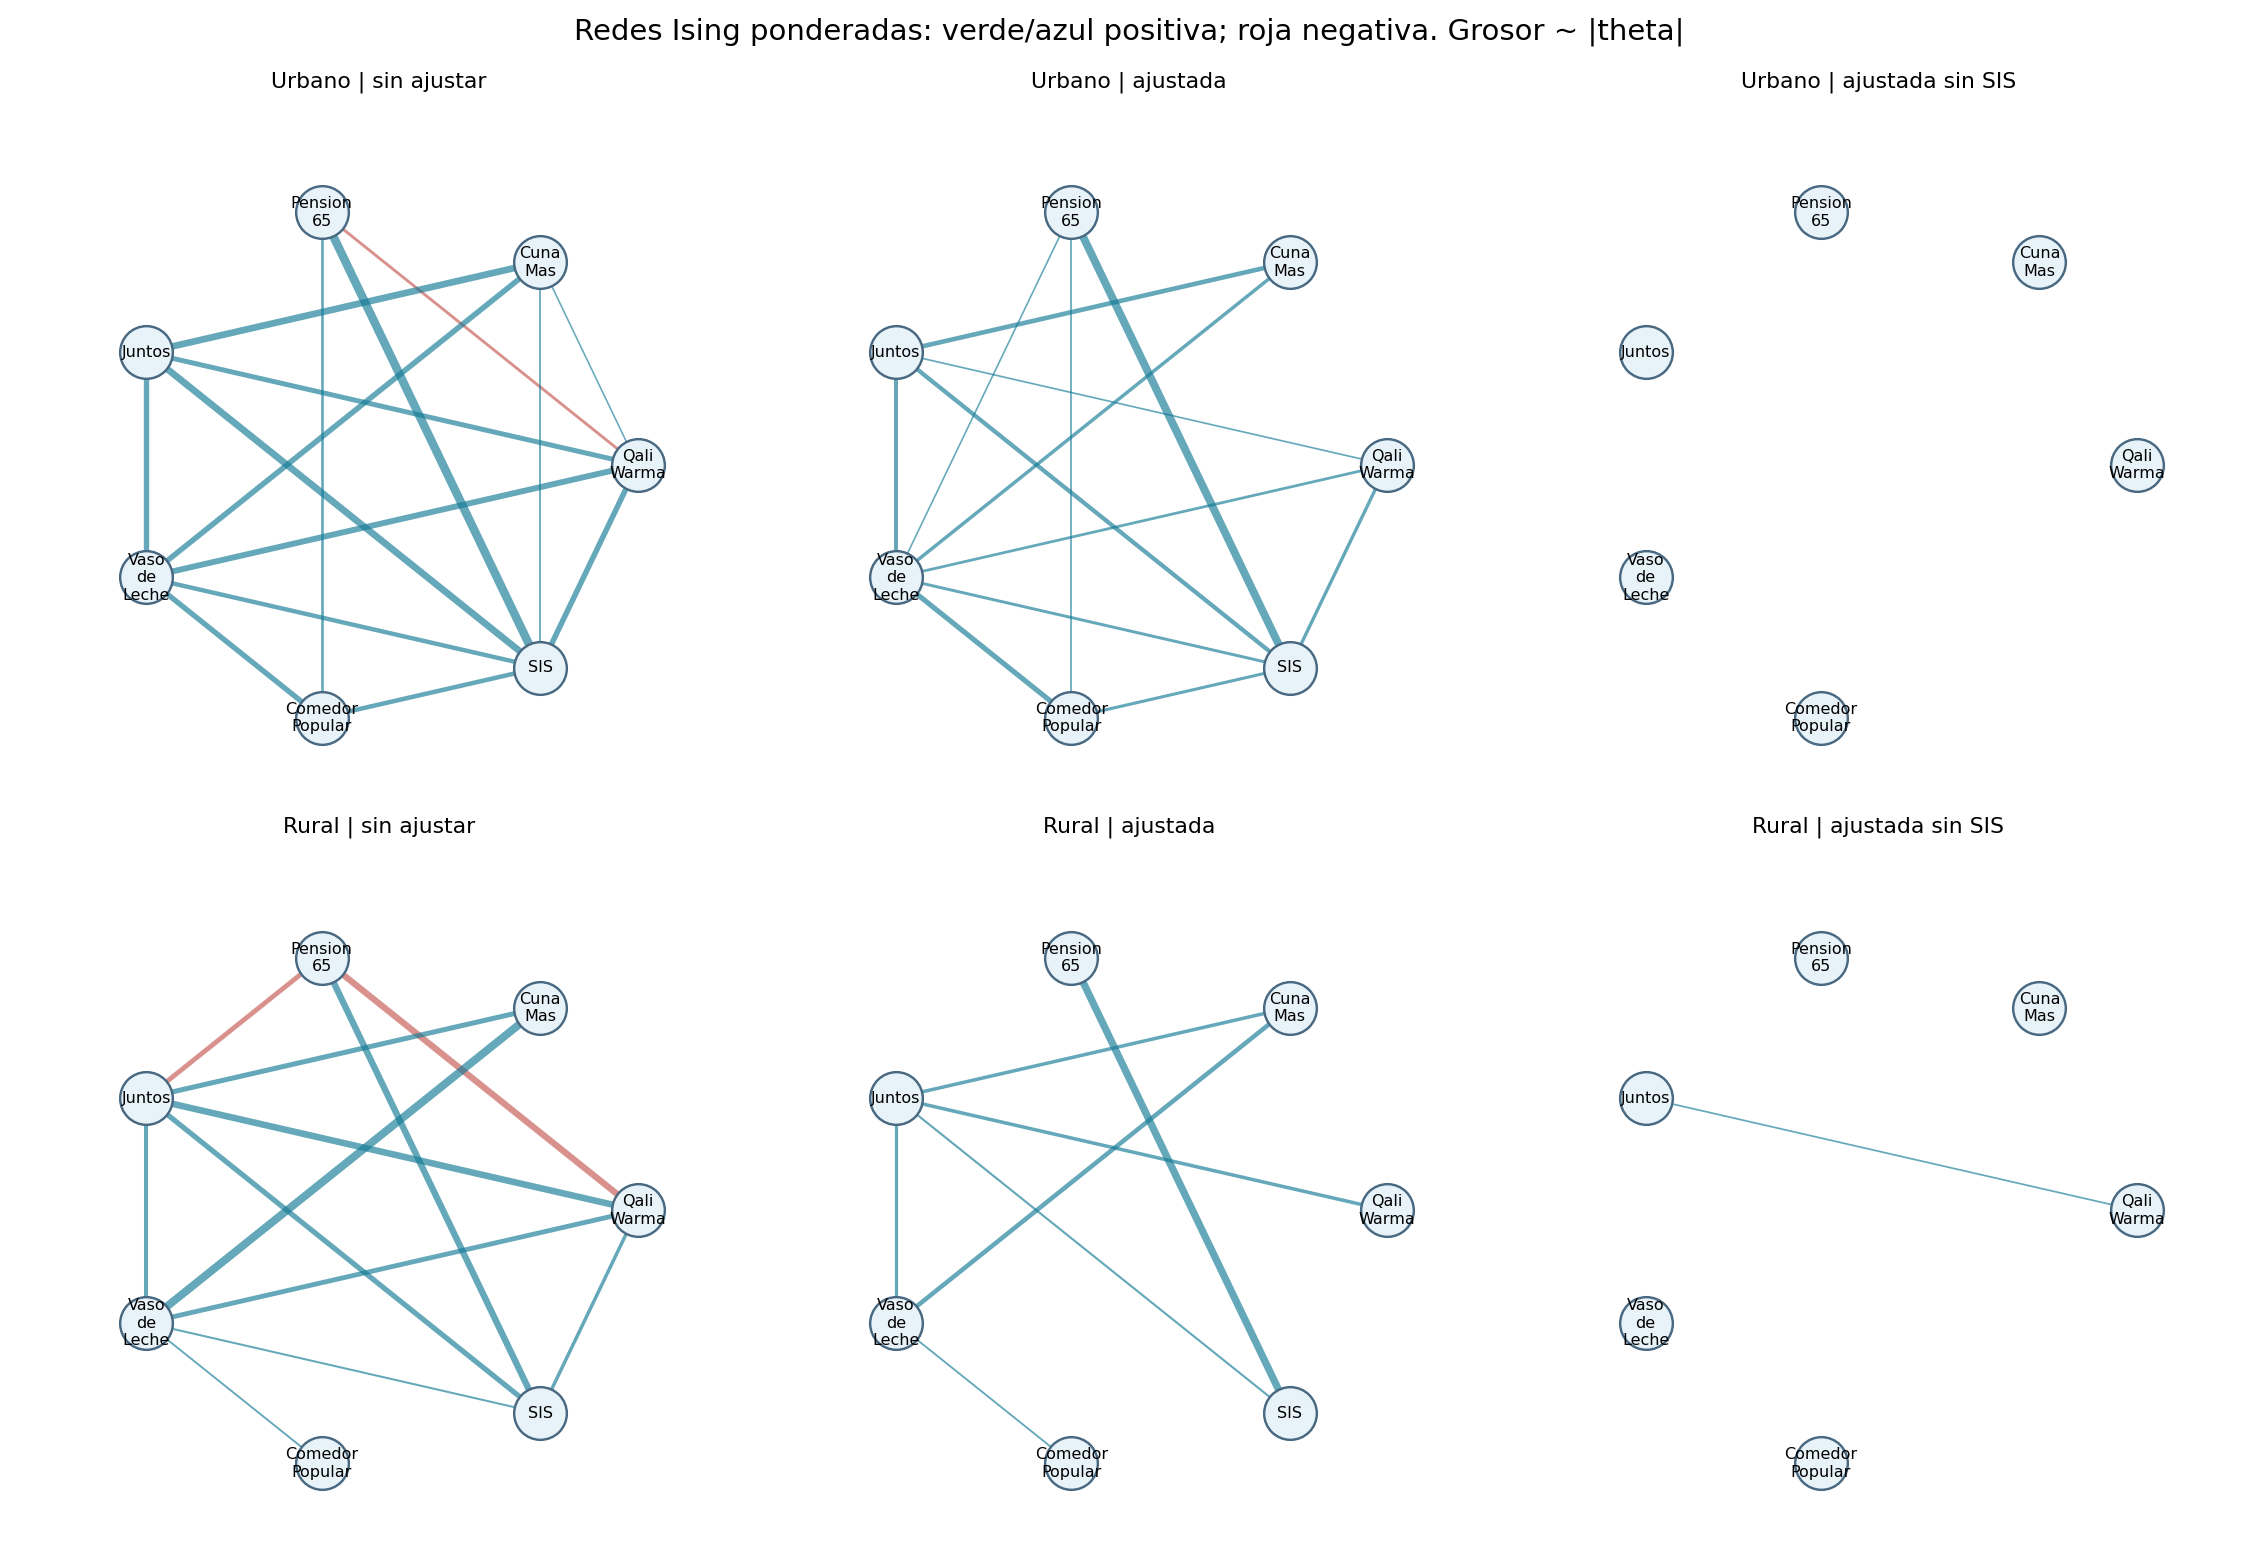

02_REDES_COSTA_SIERRA_SELVA.png


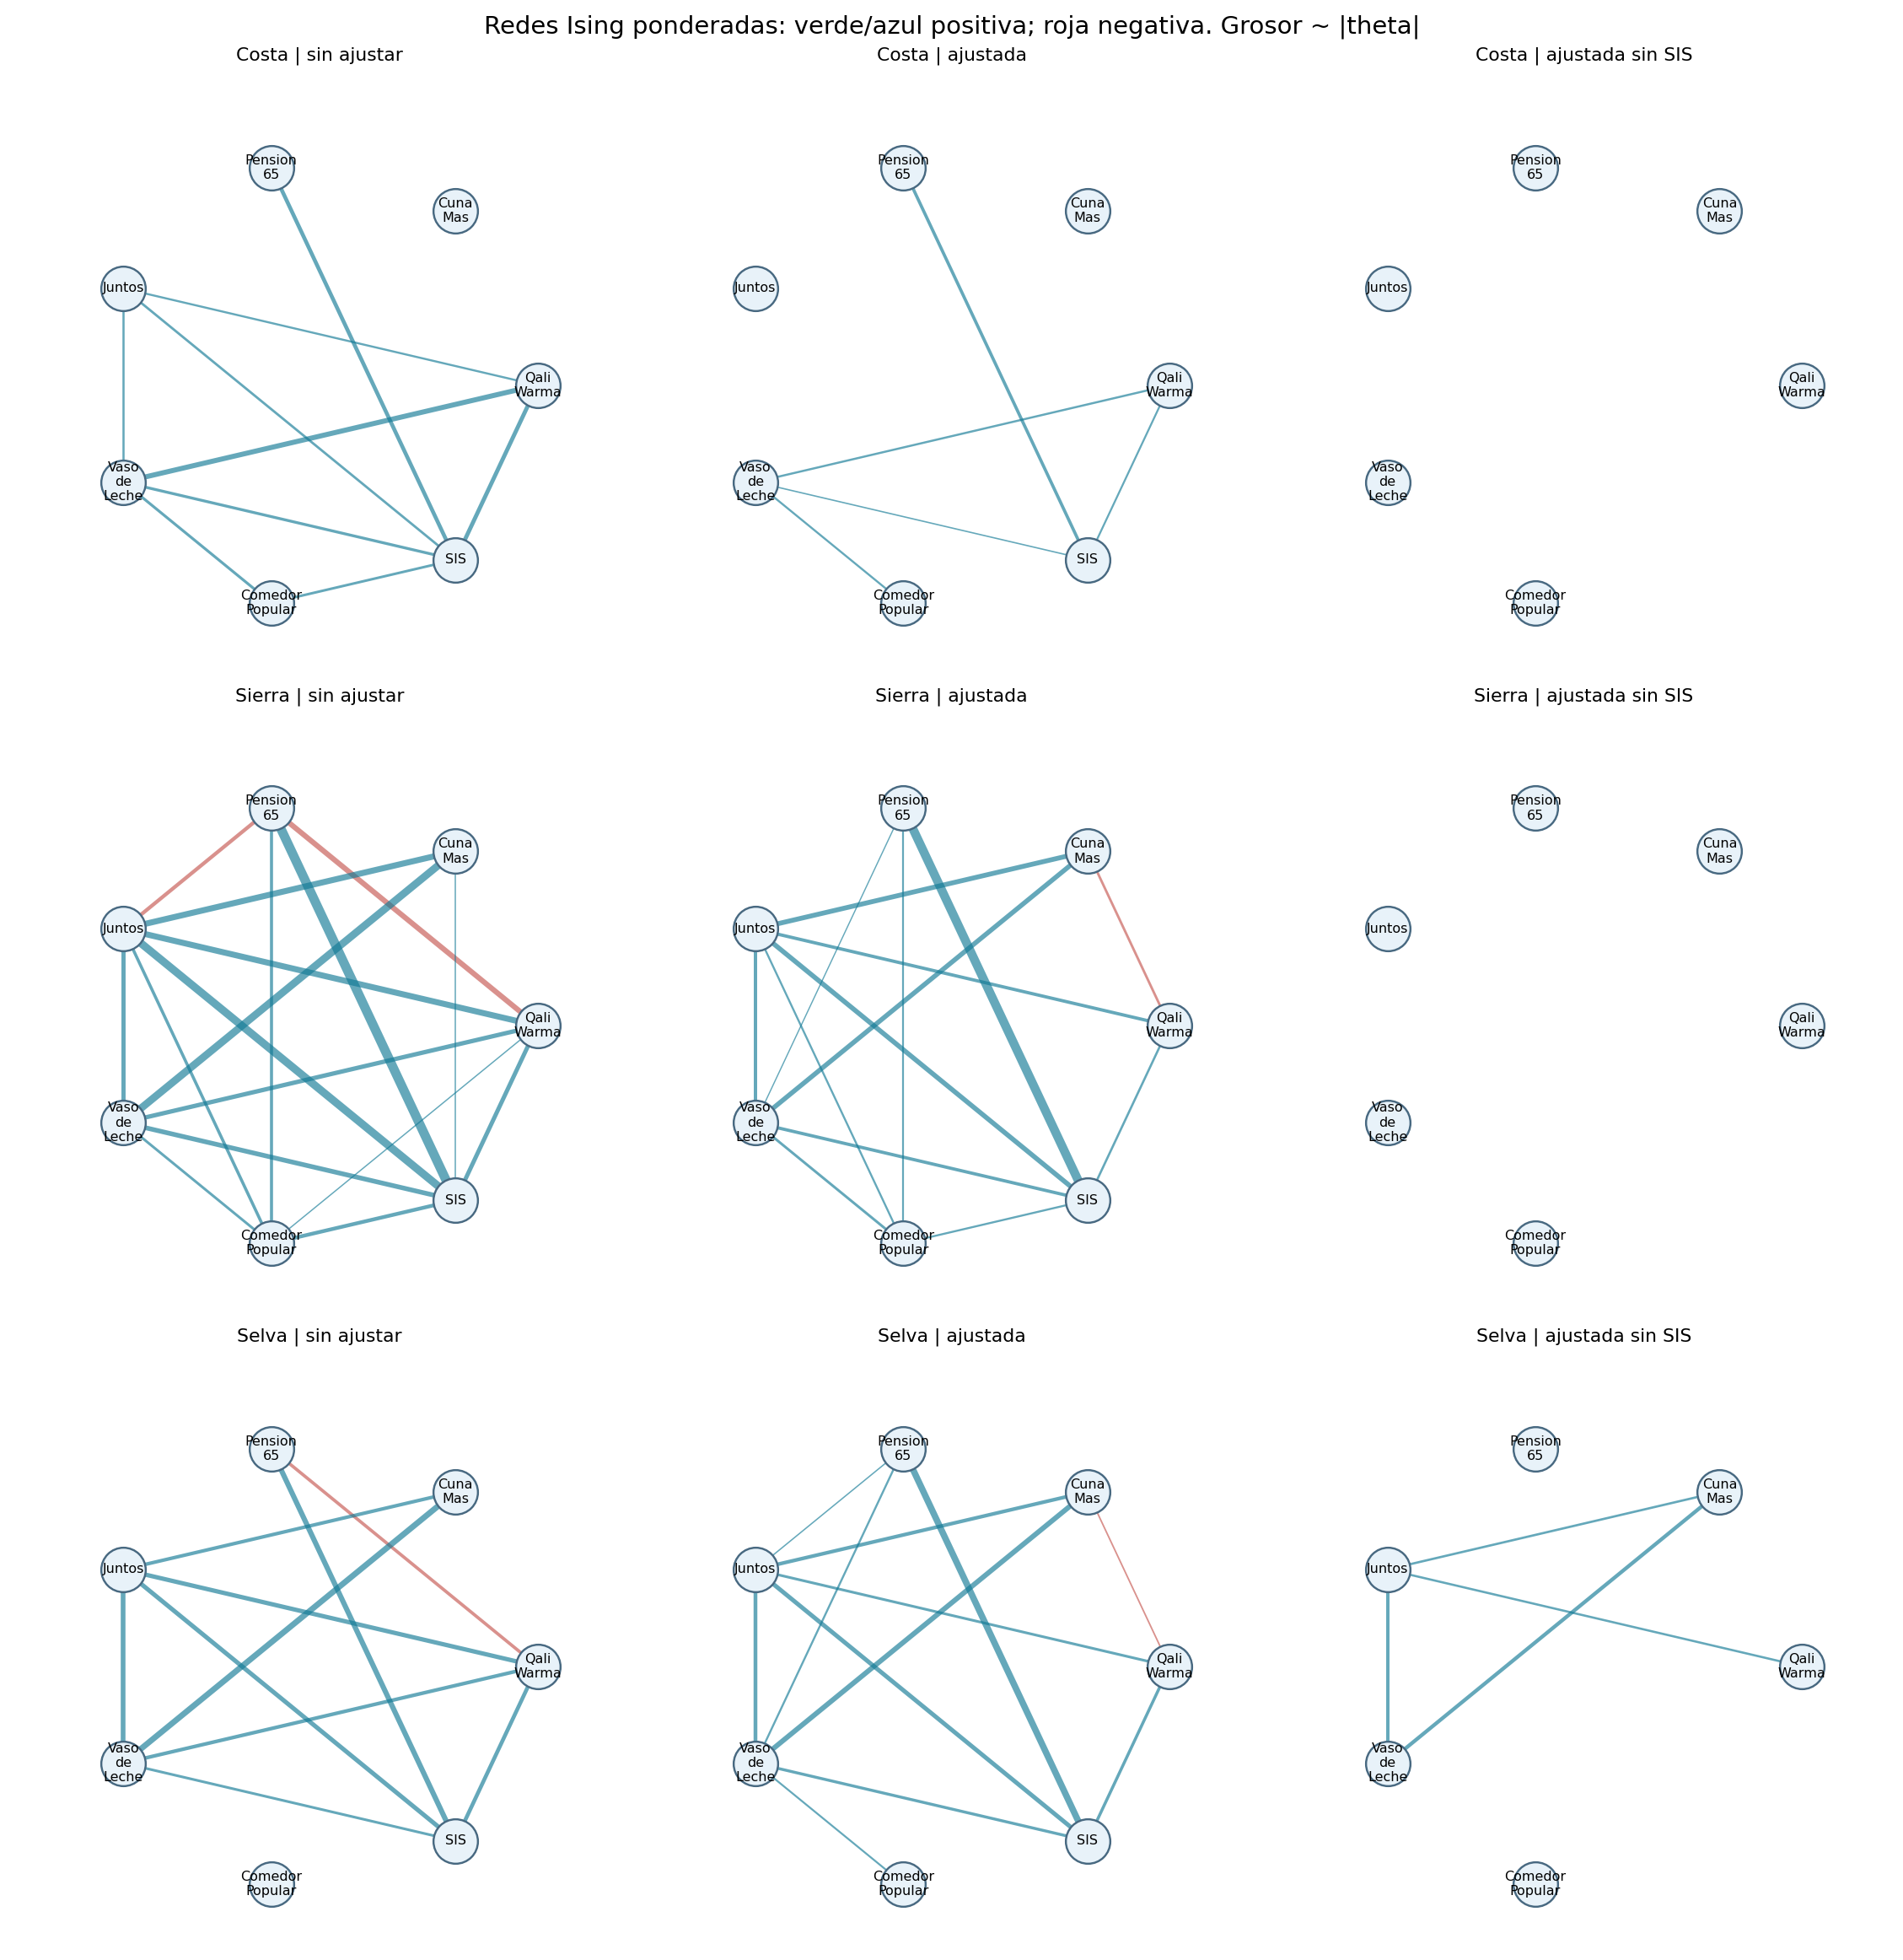

03_PRUEBAS_HETEROGENEIDAD.png


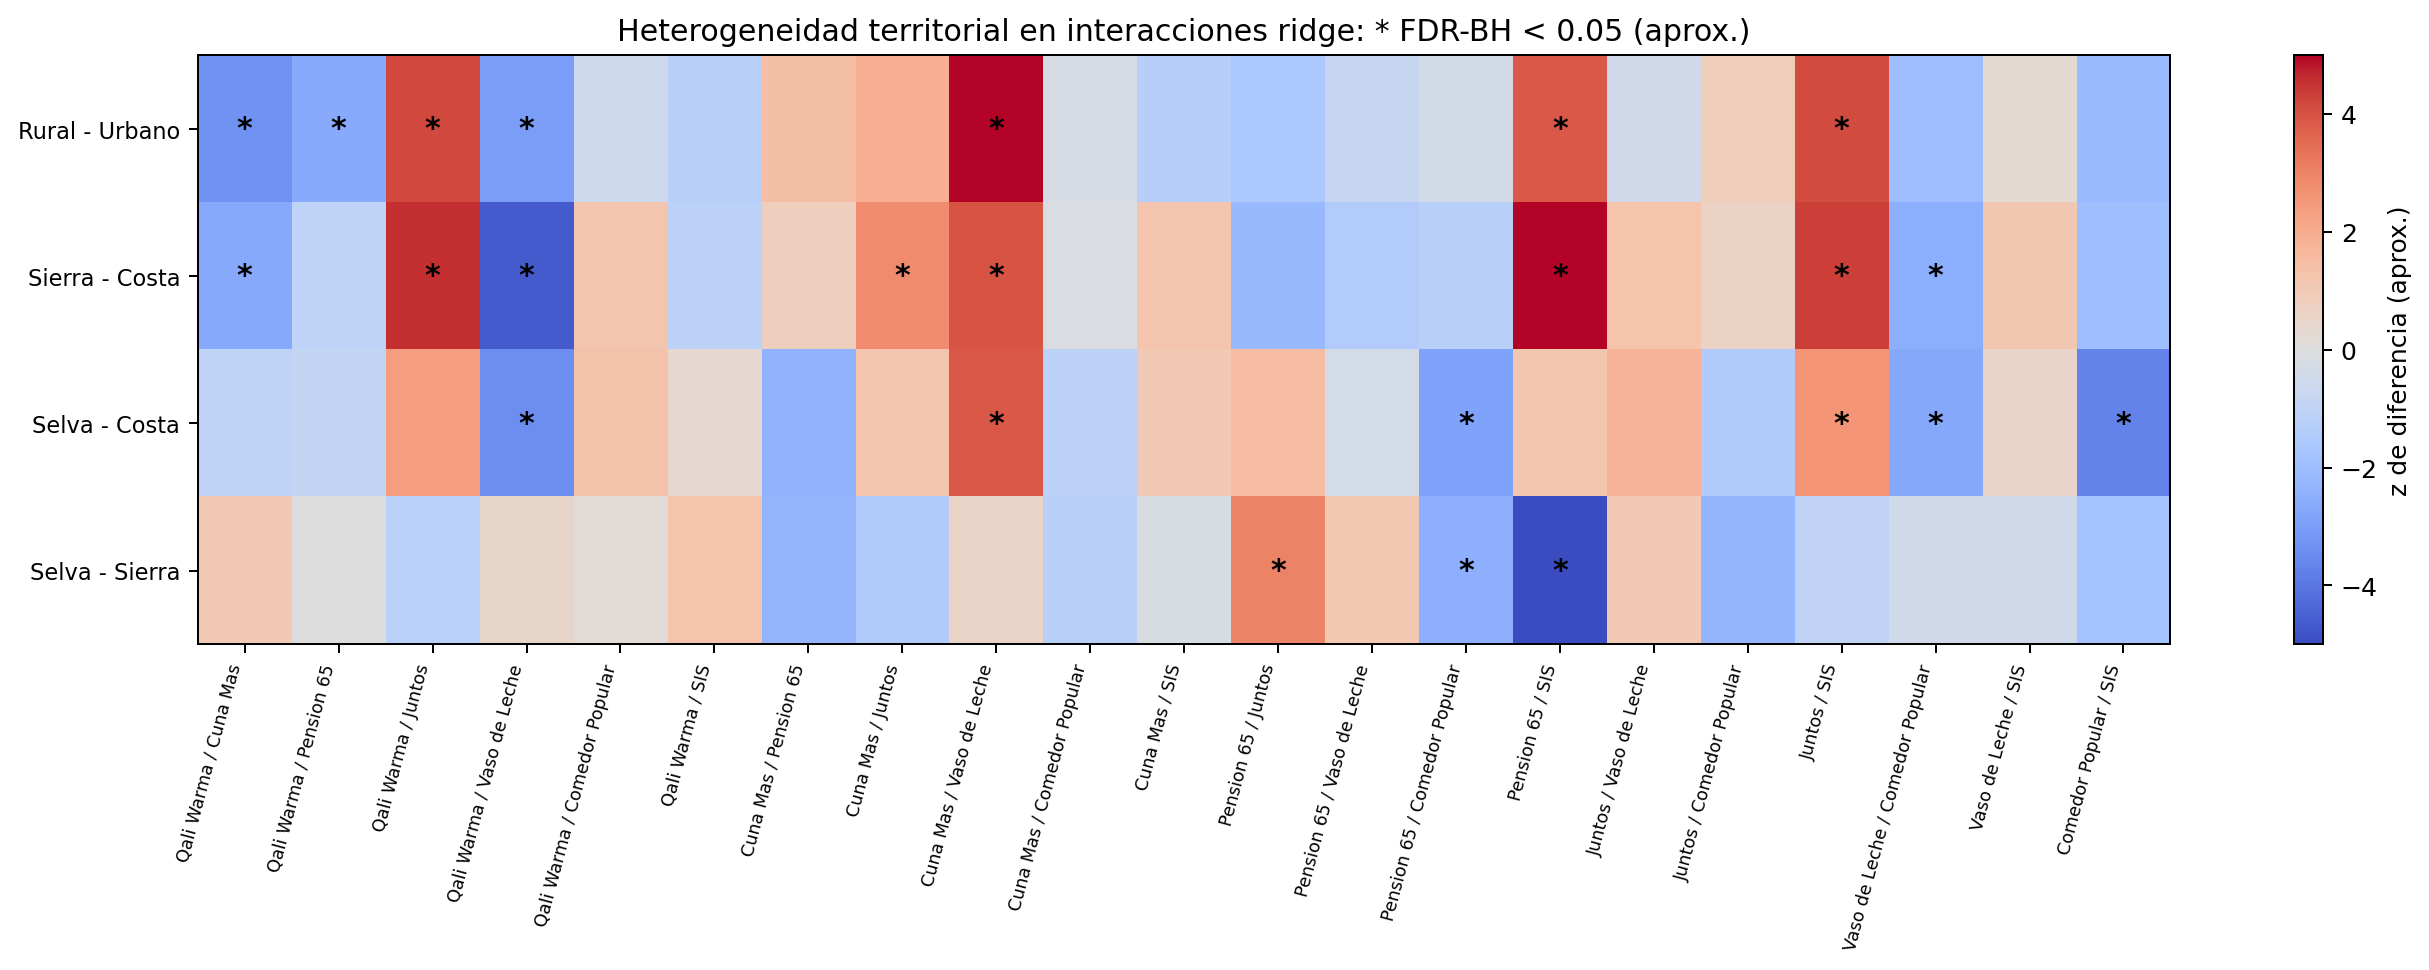

06_COVARIABLES_POR_PROGRAMA.png


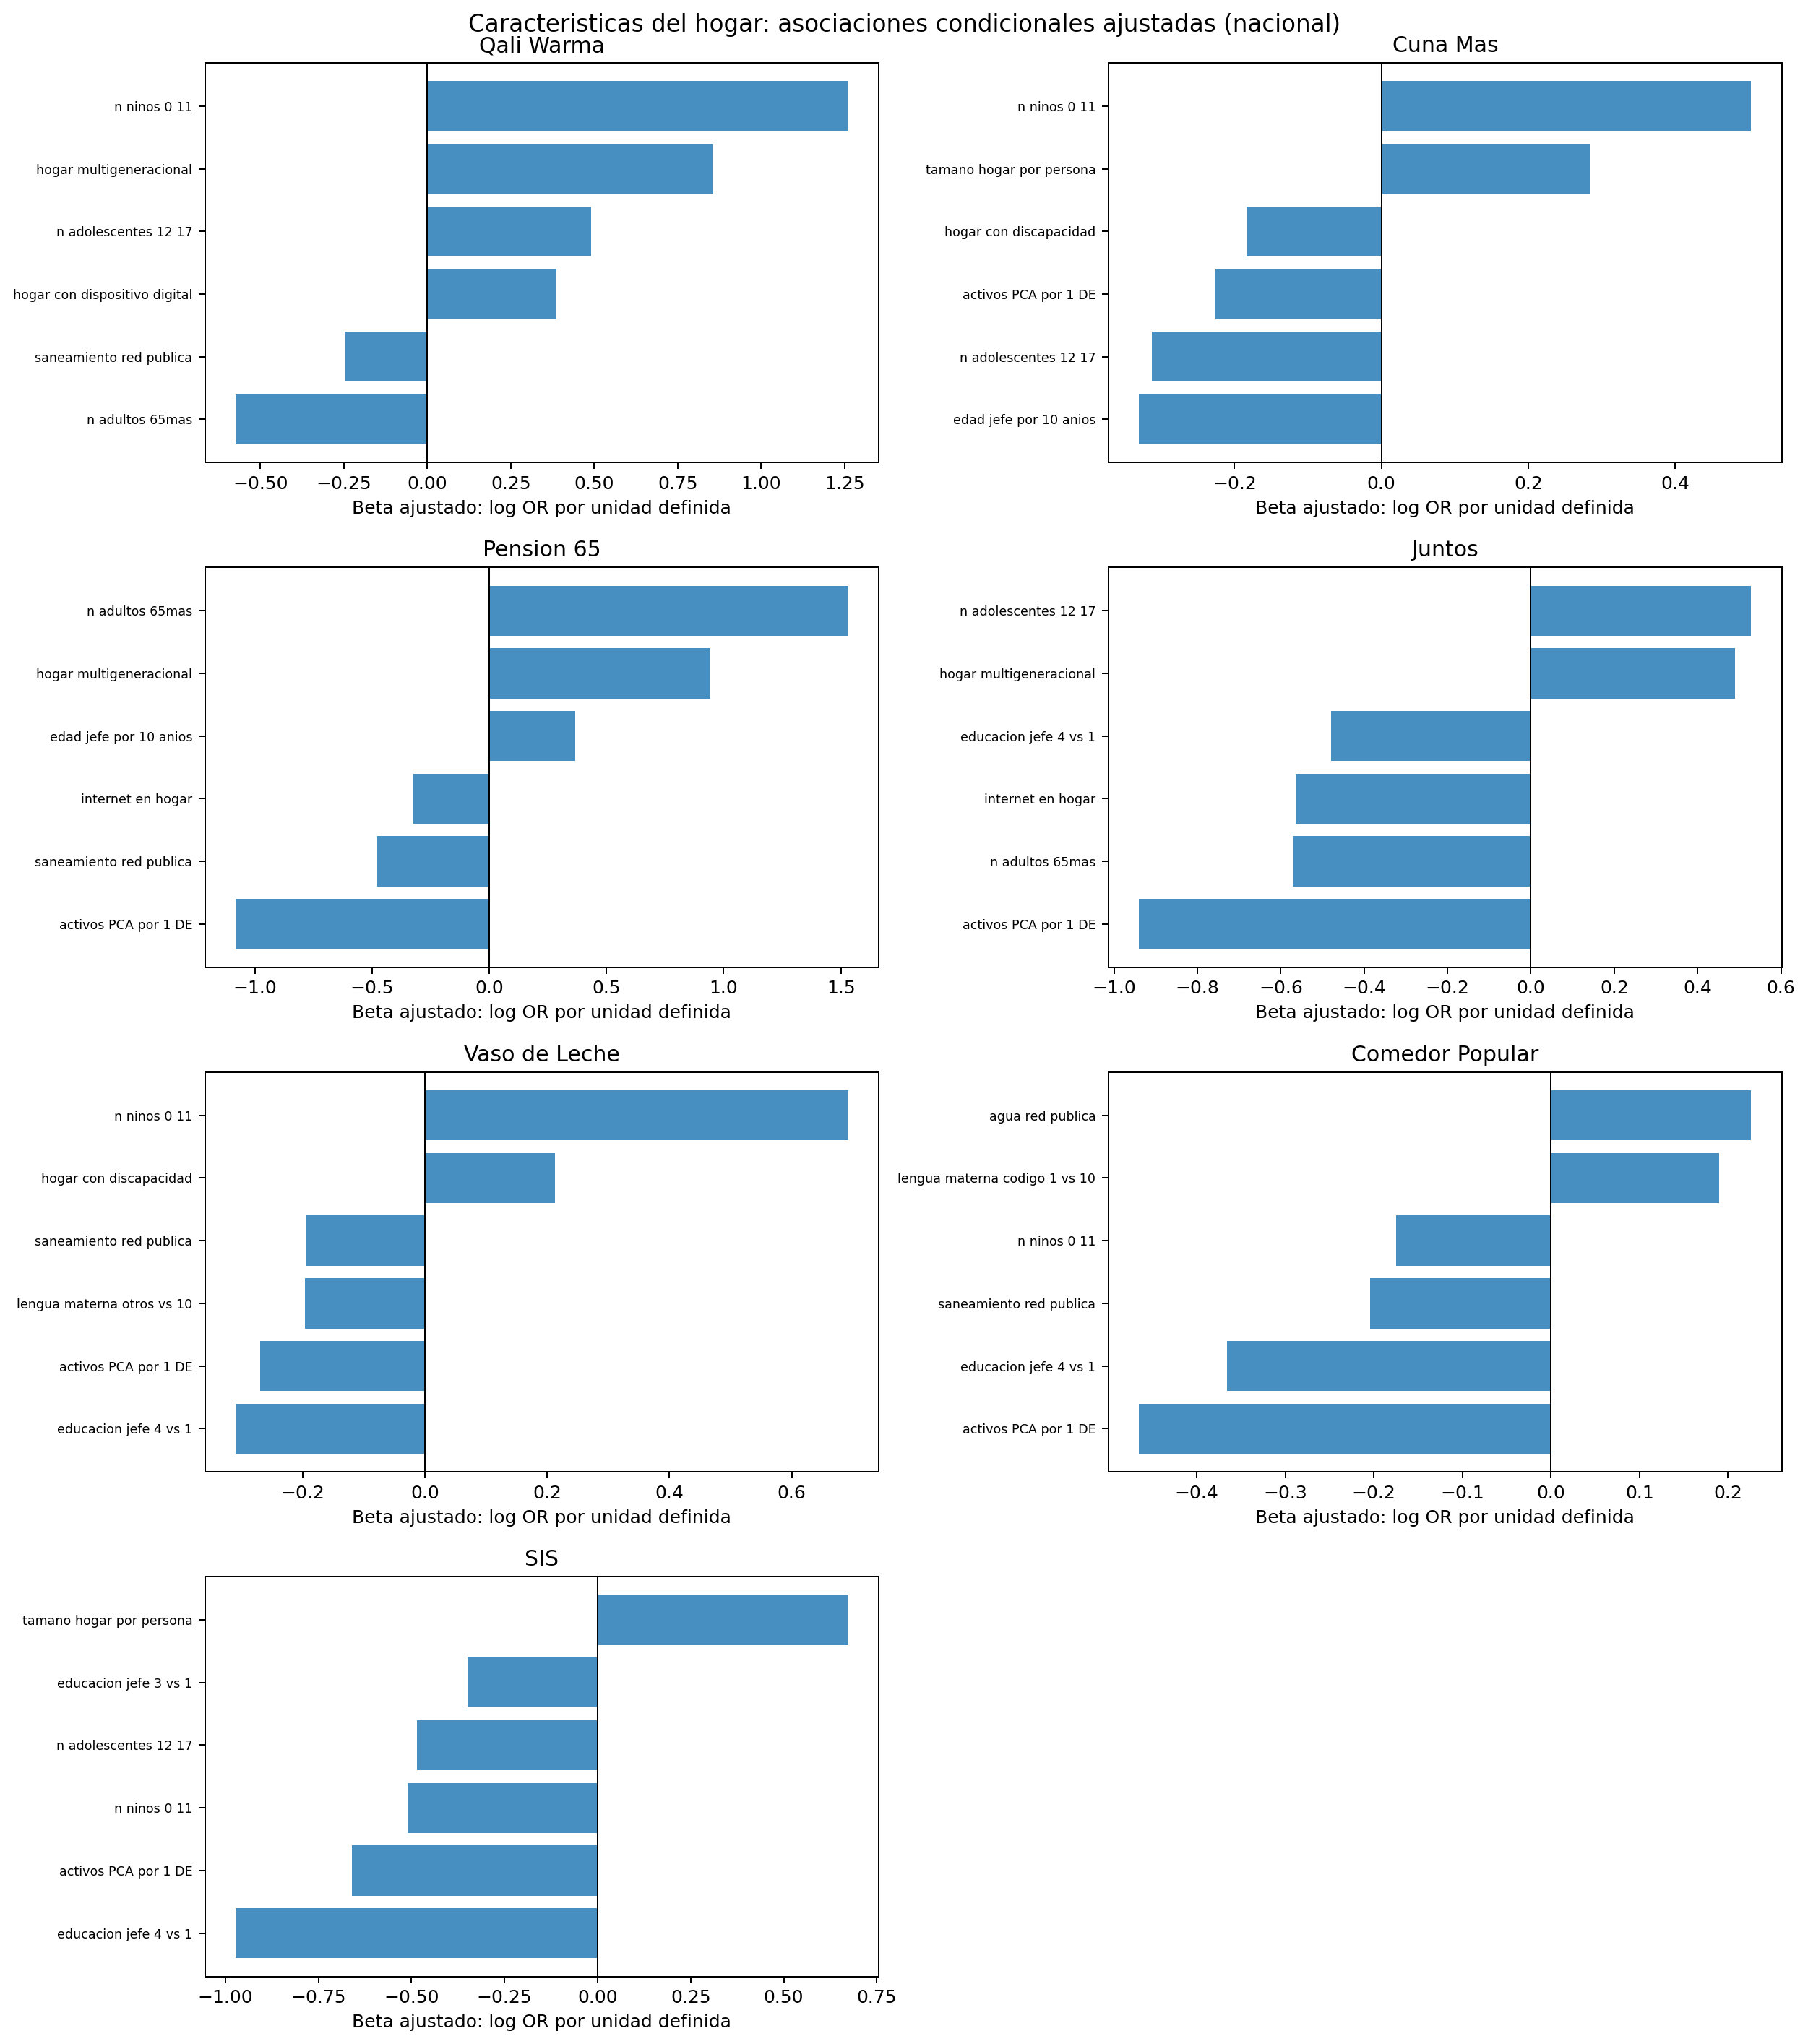

In [18]:
from IPython.display import display, Image, Markdown
print("\nResumen de redes principales:")
display(modelos_resumen[modelos_resumen.ambito.isin(['nacional','area','region_natural'])][['ambito','territorio','modelo','n_nodos','n_aristas','lambda_1SE','estado']])
print("\nPruebas globales de heterogeneidad (aproximadas):")
display(het_globales)
print("\nContrastes por arista con FDR<0.05 (interpretacion exploratoria):")
display(het_contrastes[het_contrastes.FDR_5pct].sort_values('p_FDR_BH')[['comparacion','programa_1','programa_2','delta_theta','p_FDR_BH','menor_celda_2x2']].head(30))
for figura in ['01_REDES_URBANO_RURAL.png','02_REDES_COSTA_SIERRA_SELVA.png','03_PRUEBAS_HETEROGENEIDAD.png','06_COVARIABLES_POR_PROGRAMA.png']:
 print(figura)
 display(Image(filename=str(SALIDA/figura)))


## Diagnóstico complementario de multicolinealidad (VIF)


In [19]:
from pathlib import Path
import pandas as pd,numpy as np,os
RAIZ=Path(os.getenv('ENAPRES_CARPETA','/mnt/data' if Path('/mnt/data/ENAPRES2025.xlsx').exists() else str(Path.cwd())))
p=RAIZ/'ENAPRES2025.xlsx'
d=pd.read_excel(p)
w=d.factor_hogar.to_numpy(dtype=float)
Z=pd.DataFrame({
'edad_jefe_por_10_anios':d.edad_jefe/10.,'tamano_hogar_por_persona':d.tamano_hogar,
'n_ninos_0_11':d.n_ninos_0_11,'n_adolescentes_12_17':d.n_adolescentes_12_17,
'n_adultos_65mas':d.n_adultos_65mas,
'proporcion_mujeres_por_25pp':4*d.n_mujeres/d.tamano_hogar.clip(lower=1),
'activos_PCA_por_1_DE':(d.indice_activos_pca-np.average(d.indice_activos_pca,weights=w))/np.sqrt(np.average((d.indice_activos_pca-np.average(d.indice_activos_pca,weights=w))**2,weights=w)),
'hogar_multigeneracional':d.hogar_multigeneracional,'hogar_con_discapacidad':d.hogar_con_discapacidad,
'agua_red_publica':d.agua_red_publica,'saneamiento_red_publica':d.saneamiento_red_publica,
'electricidad_red_publica':d.electricidad_red_publica,'internet_en_hogar':d.internet_en_hogar,
'hogar_con_dispositivo_digital':d.hogar_con_dispositivo_digital,
'jefa_mujer_vs_hombre':(d.sexo_jefe==2).astype(float),
'educacion_jefe_2_vs_1':(d.educacion_jefe_4niveles==2).astype(float),
'educacion_jefe_3_vs_1':(d.educacion_jefe_4niveles==3).astype(float),
'educacion_jefe_4_vs_1':(d.educacion_jefe_4niveles==4).astype(float),
'lengua_materna_codigo_1_vs_10':(d.lengua_materna_jefe==1).astype(float),
'lengua_materna_codigo_2_vs_10':(d.lengua_materna_jefe==2).astype(float),
'lengua_materna_otros_vs_10':(~d.lengua_materna_jefe.isin([1,2,10])).astype(float),
'indigena_si_vs_no':(d.jefe_pertenece_pueblo_indigena==1).astype(float),
'indigena_sin_respuesta_vs_no':d.jefe_pertenece_pueblo_indigena.isna().astype(float)
})
scopes={'Nacional':np.ones(len(d),dtype=bool),'Urbano':d.area.eq(1).to_numpy(),
'Rural':d.area.eq(2).to_numpy(),'Costa':d.region_natural.eq(1).to_numpy(),
'Sierra':d.region_natural.eq(2).to_numpy(),'Selva':d.region_natural.eq(3).to_numpy()}
records=[];condition=[]
for name,mask in scopes.items():
 a=Z.to_numpy(dtype=float)[mask];wp=w[mask];mu=np.average(a,axis=0,weights=wp)
 sd=np.sqrt(np.average((a-mu)**2,axis=0,weights=wp));active=sd>1e-7
 std=(a[:,active]-mu[active])/sd[active]
 R=np.cov(std,rowvar=False,aweights=wp)
 inv=np.linalg.pinv(R,rcond=1e-10)
 vifs=np.diag(inv)
 eig=np.linalg.eigvalsh(R)
 condition.append({'territorio':name,'hogares':len(a),'variables_con_variacion':int(active.sum()),
  'condicion_correlacion':float(np.max(eig)/max(1e-12,np.min(eig))),'VIF_max':float(vifs.max()),
  'VIF_mayor_5':int((vifs>5).sum()),'VIF_mayor_10':int((vifs>10).sum())})
 for c,v in zip(Z.columns[active],vifs):records.append({'territorio':name,'variable':c,'VIF_ponderado_aprox':float(v),'alerta_5':v>5,'alerta_10':v>10})
out=RAIZ/'ENAPRES2025_ISING_CORREGIDO'/'RESULTADOS'/'DIAGNOSTICO_VIF_COMPLEMENTARIO.xlsx'
out.parent.mkdir(parents=True,exist_ok=True)
with pd.ExcelWriter(out,engine='openpyxl') as writer:
 pd.DataFrame(condition).to_excel(writer,sheet_name='Condicion_por_territorio',index=False)
 pd.DataFrame(records).to_excel(writer,sheet_name='VIF_por_variable',index=False)
print(pd.DataFrame(condition).to_string(index=False))
print('\nTOP NACIONAL')
print(pd.DataFrame(records).query('territorio=="Nacional"').sort_values('VIF_ponderado_aprox',ascending=False).head(8).to_string(index=False))
print('ARCHIVO',out)

from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter
wb=load_workbook(out)
for ws in wb:
 ws.freeze_panes='A2';ws.sheet_view.showGridLines=False;ws.auto_filter.ref=ws.dimensions
 for h in ws[1]:
  h.fill=PatternFill('solid',fgColor='16364C');h.font=Font(bold=True,color='FFFFFF')
  h.alignment=Alignment(wrap_text=True)
 for j in range(1,ws.max_column+1):
  ws.column_dimensions[get_column_letter(j)].width=min(36,max(14,len(str(ws.cell(1,j).value))+5))
wb.save(out)


territorio  hogares  variables_con_variacion  condicion_correlacion  VIF_max  VIF_mayor_5  VIF_mayor_10
  Nacional    36184                       23              17.428120 3.334980            0             0
    Urbano    22269                       23              14.587934 2.751554            0             0
     Rural    13915                       23              28.609056 4.620431            0             0
     Costa    12919                       23              14.615797 2.669862            0             0
    Sierra    15083                       23              20.970273 3.621711            0             0
     Selva     8182                       23              22.398793 4.356893            0             0

TOP NACIONAL
territorio                 variable  VIF_ponderado_aprox  alerta_5  alerta_10
  Nacional     activos_PCA_por_1_DE             3.334980     False      False
  Nacional tamano_hogar_por_persona             3.025786     False      False
  Nacional   edad_jefe_p